# Modelamiento predictivo integrado del incumplimiento de plazos

**Evaluación Sumativa 3 · MCDI501 Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello

| | |
|---|---|
| **Grupo** | 6 |
| **Integrantes** | Marco Álvarez Araya · Ricardo Jaramillo |
| **Docente** | Dr. Jean Paul Maidana González |
| **Fecha** | 28-10-2026 |
| **Dataset** | E-Commerce Shipping Data (Prachi13, Kaggle): 10.999 envíos, 12 variables |
| **Repositorio** | https://github.com/RJaramilloP/mcdi501-ecommerce-grupo6 |

## Propósito y progresión del proyecto

| Fase | Pregunta | Hallazgo que hereda S3 |
|---|---|---|
| **S1** · Exploración e inferencia | ¿Qué características se asocian al retraso? | Descuento, peso, importancia y otras variables asociadas al retraso; el bloque ID ≤ 3.135 tiene 100 % de retrasos y descuentos > 10 que separan las clases. Sin faltantes. |
| **S2** · Validación y remuestreo | ¿Qué resultados de S1 se sostienen? | Casi todo depende del bloque inicial: en ID > 3.135 ninguna correlación es estable y solo la importancia alta conserva dirección y magnitud. Ocho recomendaciones para S3. |
| **F2** · Primer modelo | ¿Predice un modelo simple en ID > 3.135? | Faltantes MCAR inducidos (máscara y partición guardadas); logística con AUC = 0,515, no mejor que el azar (p = 0,107). |
| **S3** · Modelamiento integrado | ¿Qué modelo usar, qué tan estable es y qué cambia según cómo se traten los faltantes? | Este notebook. |

Este notebook es el **notebook maestro** de la Sumativa 3. Sigue las secciones de la plantilla y la indicación del docente: partición 70/30 estratificada dentro de ID > 3.135; tres regresiones logísticas (variables validadas, stepwise según AIC y un modelo reducido); VIF; matriz de confusión, recall y AUC; y bootstrap de los coeficientes del mejor modelo.

| Sección | Contenido | Criterio de la rúbrica |
|---|---|---|
| 1 | Faltantes: referencia a S1 y F2, imputación por regresión lineal múltiple, comparación de estrategias contra los valores verdaderos | Imputación (21 pts) |
| 2 | Tres logísticas, bootstrap de 10.000 remuestras del mejor modelo, diagnóstico de supuestos, desempeño | Clasificación (30) y bootstrap (30) |
| 3 | Modelo final ajustado con cada estrategia de faltantes y con los valores verdaderos | Impacto de la imputación (9) |
| 4 | Contraste con el conjunto completo, recomendaciones de S2 ejecutadas y síntesis | Informe integrado (9) |

**Reproducibilidad.** Semilla 42, huella SHA-256 del CSV, la misma máscara MCAR y la misma partición de F2 (verificadas), imputación y estandarización ajustadas solo con el entrenamiento, y todas las tablas y figuras exportadas a `S3/resultados/`. La última celda verifica que las cifras de la síntesis coincidan con los cálculos.

## 0. Entorno, datos e insumos

### 0.1 Librerías, semilla y constantes

In [1]:
import hashlib
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from IPython.display import display, Markdown

SEED = 42
CORTE_ID = 3135
OBJETIVO = "Reached.on.Time_Y.N"              # 1 = fuera de plazo
VARS_FALTANTES = ["Cost_of_the_Product", "Weight_in_gms"]
PROP_FALTANTES = 0.12
B_BOOT = 10_000            # remuestras bootstrap de coeficientes y del AUC
B_PERM = 10_000            # permutaciones del AUC
B_SEL = 1_000              # remuestras para la frecuencia de selección del stepwise
K_CV = 5                   # particiones de la validación cruzada
SHA_ESPERADO = "dcdc3fd8f0507ec400174ef70d88d634321cc2ce8f4ea11bf4e8c847fdd325b3"
assert min(B_BOOT, B_PERM) >= 10_000

COLORES = {"M1": "#2A74B0", "M2": "#C7781F", "M3": "#26734D"}
C_FUERA, C_GRIS, C_VERDADERO = "#BC5A45", "#7F7F7F", "#262626"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8, "axes.titlesize": 8.5,
    "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "lines.linewidth": 1.2, "axes.linewidth": 0.7, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9A9A9A", "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

RAIZ = Path.cwd()
while not ((RAIZ / "S1").is_dir() and (RAIZ / "datos").is_dir()):
    if RAIZ.parent == RAIZ:
        raise FileNotFoundError("No se encontró la raíz del repositorio (carpetas S1/ y datos/)")
    RAIZ = RAIZ.parent
S1_TABLAS = RAIZ / "S1" / "resultados" / "tablas"
S2_TABLAS = RAIZ / "S2" / "resultados" / "tablas"
F2_TABLAS = RAIZ / "F2" / "resultados" / "tablas"
DIR_DERIVADOS = RAIZ / "datos" / "derivados"
DIR_TABLAS = RAIZ / "S3" / "resultados" / "tablas"
DIR_FIGURAS = RAIZ / "S3" / "resultados" / "figuras"
for d in (DIR_TABLAS, DIR_FIGURAS):
    d.mkdir(parents=True, exist_ok=True)


def guardar_tabla(tabla, nombre, index=False):
    # Exporta la tabla a S3/resultados/tablas/<nombre>.csv y la devuelve para mostrarla.
    tabla.to_csv(DIR_TABLAS / f"{nombre}.csv", index=index, encoding="utf-8")
    return tabla


def es(x, d=2):
    t = f"{x:,.{d}f}"
    return t.replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


def pct(x, d=1):
    return es(100 * x, d) + " %"


def _marca_es(v, pos=None):
    t = f"{v:,.10g}"
    return t.replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


def guardar_figura(fig, nombre):
    for ax in fig.axes:
        for eje in (ax.xaxis, ax.yaxis):
            if eje.get_scale() == "linear" and type(eje.get_major_formatter()) is matplotlib.ticker.ScalarFormatter:
                eje.set_major_formatter(matplotlib.ticker.FuncFormatter(_marca_es))
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", bbox_inches="tight", facecolor="white")


leer = lambda carpeta, nombre, **kw: pd.read_csv(carpeta / f"{nombre}.csv", **kw)
T0 = time.time()
print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"scipy {scipy.__version__} · statsmodels {statsmodels.__version__} · scikit-learn {sklearn.__version__} · "
      f"matplotlib {matplotlib.__version__}")
print(f"Semilla = {SEED} · B_BOOT = {B_BOOT:,} · B_PERM = {B_PERM:,} · B_SEL = {B_SEL:,} · validación cruzada {K_CV} particiones")

Python 3.13.16 · numpy 2.5.3 · pandas 3.0.5 · scipy 1.18.1 · statsmodels 0.15.0 · scikit-learn 1.9.1 · matplotlib 3.11.2
Semilla = 42 · B_BOOT = 10,000 · B_PERM = 10,000 · B_SEL = 1,000 · validación cruzada 5 particiones


### 0.2 Datos, máscara MCAR y partición de F2

S3 no regenera los faltantes ni la partición: los lee de `datos/derivados/`, donde los dejó F2, y verifica dos cosas. Primero, que la máscara coincide con la rutina MCAR documentada en F2 (semilla 42, 12 % por variable). Segundo, que la partición mantiene la estratificación. Así la Formativa 2 y la Sumativa 3 trabajan exactamente con el mismo dataset «con faltantes», como indican las instrucciones del curso.

In [2]:
ruta_csv = RAIZ / "datos" / "originales" / "ecommerce-shipping.csv"
if not ruta_csv.is_file():
    raise FileNotFoundError(f"Falta el CSV original en {ruta_csv} (ver README, sección Datos)")
assert hashlib.sha256(ruta_csv.read_bytes()).hexdigest() == SHA_ESPERADO
df_original = pd.read_csv(ruta_csv)
assert df_original.shape == (10_999, 12) and int(df_original.isna().sum().sum()) == 0
assert df_original.loc[df_original["ID"] <= CORTE_ID, OBJETIVO].eq(1).all()

mascara = pd.read_csv(DIR_DERIVADOS / "mascara_mcar.csv")
particion = pd.read_csv(DIR_DERIVADOS / "particion_70_30.csv")

# Control 1: la máscara es la de la rutina MCAR de F2 (misma semilla y mismo orden de sorteo).
rng = np.random.default_rng(SEED)
k_faltantes = round(PROP_FALTANTES * len(df_original))
filas = []
for v in VARS_FALTANTES:
    pos = rng.choice(len(df_original), size=k_faltantes, replace=False)
    filas += [{"variable": v, "ID": int(i)} for i in df_original["ID"].to_numpy()[pos]]
assert pd.DataFrame(filas).sort_values(["variable", "ID"], ignore_index=True).equals(mascara)

df = df_original.copy()
for v in VARS_FALTANTES:
    df.loc[df["ID"].isin(mascara.loc[mascara["variable"].eq(v), "ID"]), v] = np.nan

# Control 2: la partición cubre exactamente ID > 3.135 y conserva la tasa de retraso.
sub = df.loc[df["ID"] > CORTE_ID].merge(particion, on="ID", how="left", validate="one_to_one")
assert sub["conjunto"].notna().all() and len(sub) == 7_864
ent0 = sub.loc[sub["conjunto"].eq("entrenamiento")].drop(columns="conjunto").reset_index(drop=True)
pru0 = sub.loc[sub["conjunto"].eq("prueba")].drop(columns="conjunto").reset_index(drop=True)
assert abs(ent0[OBJETIVO].mean() - pru0[OBJETIVO].mean()) < 0.001
VERDADERO = df_original.set_index("ID")

control = guardar_tabla(pd.DataFrame([
    {"control": "SHA-256 del CSV", "resultado": "coincide con S1, S2 y F2"},
    {"control": "Máscara MCAR (datos/derivados/mascara_mcar.csv)", "resultado": f"idéntica a la rutina de F2: {k_faltantes:,} valores por variable".replace(",", ".")},
    {"control": "Partición 70/30 (datos/derivados/particion_70_30.csv)",
     "resultado": f"entrenamiento {len(ent0):,} · prueba {len(pru0):,} · tasas {ent0[OBJETIVO].mean():.4f} y {pru0[OBJETIVO].mean():.4f}".replace(",", ".")},
]), "s3_tab00_control_insumos")
display(control)

,control,resultado
0,SHA-256 del CSV,"coincide con S1, S2 y F2"
1,Máscara MCAR (datos/derivados/mascara_mcar.csv),idéntica a la rutina de F2: 1.320 valores por ...
2,Partición 70/30 (datos/derivados/particion_70_...,entrenamiento 5.504 · prueba 2.360 · tasas 0.4...


## 1. Manejo inteligente de datos faltantes

### 1.1 Referencia al análisis de faltantes de S1

S1 documentó **0 faltantes** en las 12 variables (Tabla 1 y diccionario de variables), por lo que, siguiendo las instrucciones del curso, F2 indujo faltantes de forma controlada. Los valores eliminados (12 % del costo y 12 % del peso) se eligieron completamente al azar, de modo que el **mecanismo es MCAR por construcción**, no por supuesto. F2 lo verificó con 20 contrastes entre envíos con y sin faltante: ninguno resultó significativo (p mínimo 0,061; Holm = 1). La ventaja de inducirlos es que se conocen los valores verdaderos: cada estrategia puede evaluarse por su **error de imputación**, algo imposible con faltantes reales.

In [3]:
mcar_f2 = leer(F2_TABLAS, "f2_tab03_control_mcar")
dicc = leer(S1_TABLAS, "diccionario_variables")
assert int(dicc["faltantes"].sum()) == 0
filas = []
for v in VARS_FALTANTES:
    for nombre, d in [("Completo (10.999)", df), ("ID > 3.135", sub), ("Entrenamiento", ent0), ("Prueba", pru0)]:
        filas.append({"variable": v, "conjunto": nombre, "n": len(d), "faltantes": int(d[v].isna().sum()),
                      "pct_faltantes": 100 * d[v].isna().mean()})
for nombre, d in [("Entrenamiento", ent0), ("Prueba", pru0)]:
    filas.append({"variable": "Ambas", "conjunto": nombre, "n": len(d),
                  "faltantes": int(d[VARS_FALTANTES].isna().all(axis=1).sum()),
                  "pct_faltantes": 100 * d[VARS_FALTANTES].isna().all(axis=1).mean()})
resumen_faltantes = guardar_tabla(pd.DataFrame(filas), "s3_tab01_resumen_faltantes")
with pd.option_context("display.float_format", "{:.2f}".format):
    display(resumen_faltantes)
print(f"Control MCAR de F2: {len(mcar_f2)} contrastes, mínimo p = {mcar_f2['p'].min():.4f}, mínimo p Holm = {mcar_f2['p_holm'].min():.3f}")

,variable,conjunto,n,faltantes,pct_faltantes
0,Cost_of_the_Product,Completo (10.999),10999,1320,12.00
1,Cost_of_the_Product,ID > 3.135,7864,959,12.19
2,Cost_of_the_Product,Entrenamiento,5504,641,11.65
3,Cost_of_the_Product,Prueba,2360,318,13.47
4,Weight_in_gms,Completo (10.999),10999,1320,12.00
5,Weight_in_gms,ID > 3.135,7864,936,11.90
6,Weight_in_gms,Entrenamiento,5504,647,11.76
7,Weight_in_gms,Prueba,2360,289,12.25
8,Ambas,Entrenamiento,5504,75,1.36
9,Ambas,Prueba,2360,41,1.74


Control MCAR de F2: 20 contrastes, mínimo p = 0.0611, mínimo p Holm = 1.000


### 1.2 Imputación mediante regresión lineal múltiple

**Selección de predictores (3 a 5 por variable).** Se parte de la matriz de correlaciones de Spearman de S1 (Figura 4 de S1, recalculada sobre el archivo completo) y se aplica el criterio de estabilidad de S2: un predictor se usa solo si su correlación con la variable a imputar supera 0,1 en valor absoluto **en el completo y en ID > 3.135, con el mismo signo**. Además:

- **No se usa la variable objetivo.** Imputar con el retraso trasladaría información del resultado a los predictores del modelo.
- **No se usan llamadas ni calificación,** por la posible fuga de información que señaló S2 (recomendación 3): imputar con ellas introduciría esa información por otra vía.
- **La importancia del producto** se agrega como variable categórica porque el peso medio difiere entre sus niveles.

Las correlaciones de esta celda se calculan sobre los datos originales, igual que en S1. Es la única lectura de los valores verdaderos fuera de la evaluación del error; en la selección no interviene ningún valor eliminado de los conjuntos de modelamiento.

In [4]:
CANDIDATOS_IMP = ["Cost_of_the_Product", "Weight_in_gms", "Prior_purchases", "Discount_offered",
                  "Customer_care_calls", "Customer_rating"]
nombre_var = {"Cost_of_the_Product": "Costo", "Weight_in_gms": "Peso", "Prior_purchases": "Compras previas",
              "Discount_offered": "Descuento", "Customer_care_calls": "Llamadas", "Customer_rating": "Calificación"}
corr_s1 = df_original[CANDIDATOS_IMP].corr(method="spearman")
corr_sub = df_original.loc[df_original["ID"] > CORTE_ID, CANDIDATOS_IMP].corr(method="spearman")
filas = []
for v in VARS_FALTANTES:
    for w in CANDIDATOS_IMP:
        if w == v:
            continue
        r1, r2 = corr_s1.loc[v, w], corr_sub.loc[v, w]
        estable = (abs(r1) >= 0.1) and (abs(r2) >= 0.1) and (np.sign(r1) == np.sign(r2))
        if w in ("Customer_care_calls", "Customer_rating"):
            decision, motivo = "Excluir", "Posible fuga (S2, recomendación 3)"
        elif estable:
            decision, motivo = "Usar", "Correlación estable en ambos conjuntos"
        else:
            decision, motivo = "Excluir", "Correlación débil o dependiente del bloque"
        filas.append({"variable_a_imputar": nombre_var[v], "predictor": nombre_var[w], "rho_completo_S1": r1,
                      "rho_id_gt_3135": r2, "estable": estable, "decision": decision, "motivo": motivo})
sel_imp = guardar_tabla(pd.DataFrame(filas), "s3_tab02_predictores_imputacion")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(sel_imp)
peso_imp = df_original.loc[df_original["ID"] > CORTE_ID].groupby("Product_importance")[["Cost_of_the_Product", "Weight_in_gms"]].mean()
display(peso_imp.round(1))

,variable_a_imputar,predictor,rho_completo_S1,rho_id_gt_3135,estable,decision,motivo
0,Costo,Peso,-0.132,-0.374,True,Usar,Correlación estable en ambos conjuntos
1,Costo,Compras previas,0.194,0.230,True,Usar,Correlación estable en ambos conjuntos
2,Costo,Descuento,-0.116,0.006,False,Excluir,Correlación débil o dependiente del bloque
3,Costo,Llamadas,0.294,0.345,True,Excluir,"Posible fuga (S2, recomendación 3)"
4,Costo,Calificación,0.010,0.010,False,Excluir,"Posible fuga (S2, recomendación 3)"
5,Peso,Costo,-0.132,-0.374,True,Usar,Correlación estable en ambos conjuntos
6,Peso,Compras previas,-0.235,-0.372,True,Usar,Correlación estable en ambos conjuntos
7,Peso,Descuento,-0.316,0.001,False,Excluir,Correlación débil o dependiente del bloque
8,Peso,Llamadas,-0.233,-0.383,True,Excluir,"Posible fuga (S2, recomendación 3)"
9,Peso,Calificación,-0.005,-0.015,False,Excluir,"Posible fuga (S2, recomendación 3)"


,Cost_of_the_Product,Weight_in_gms
Product_importance,,
high,208.3,4825.6
low,218.3,3947.7
medium,214.5,4229.1


El criterio selecciona, para cada variable, a la otra variable con faltantes y a las **compras previas**, y se agrega la **importancia** (dos indicadores: media y alta, con baja como referencia). El **descuento** queda fuera aunque en S1 se correlaciona con el peso (−0,316): en ID > 3.135 esa correlación es 0,001. Es el mismo patrón de dependencia del bloque que S2 documentó para su relación con el retraso.

**Ajuste e imputación encadenada.** Cada regresión se ajusta por mínimos cuadrados **solo con los envíos de entrenamiento que tienen ambas variables observadas** (casos completos), y se aplica sin reajustar a entrenamiento y prueba. Como costo y peso se predicen mutuamente, los pocos envíos sin ninguno de los dos (75 en entrenamiento y 41 en prueba) se imputan de forma encadenada: se parte de las medianas y se alternan las dos regresiones hasta que los valores dejan de cambiar. Es la idea de la imputación por ecuaciones encadenadas (van Buuren y Groothuis-Oudshoorn, 2011) en su versión determinista.

In [5]:
def indicadores_importancia(d):
    return pd.DataFrame({"Importancia_media": d["Product_importance"].eq("medium").astype(float),
                         "Importancia_alta": d["Product_importance"].eq("high").astype(float)}, index=d.index)


PRED_IMP = {"Cost_of_the_Product": ["Weight_in_gms", "Prior_purchases"],
            "Weight_in_gms": ["Cost_of_the_Product", "Prior_purchases"]}
assert set(PRED_IMP["Cost_of_the_Product"]) == set(sel_imp.query("variable_a_imputar == 'Costo' and decision == 'Usar'")["predictor"].map({v: k for k, v in nombre_var.items()}))
assert set(PRED_IMP["Weight_in_gms"]) == set(sel_imp.query("variable_a_imputar == 'Peso' and decision == 'Usar'")["predictor"].map({v: k for k, v in nombre_var.items()}))


def diseno_imp(d, v):
    return sm.add_constant(pd.concat([d[PRED_IMP[v]].astype(float), indicadores_importancia(d)], axis=1), has_constant="add")


completos = ent0.dropna(subset=VARS_FALTANTES)
reg_imp = {v: sm.OLS(completos[v], diseno_imp(completos, v)).fit() for v in VARS_FALTANTES}
mediana_ent = completos[VARS_FALTANTES].median()


def imputar_regresion(d, tol=1e-8, max_iter=100):
    d = d.copy()
    falta = {v: d[v].isna() for v in VARS_FALTANTES}
    actual = {v: d[v].fillna(mediana_ent[v]) for v in VARS_FALTANTES}
    for it in range(1, max_iter + 1):
        cambio = 0.0
        for v in VARS_FALTANTES:
            tmp = d.assign(**actual)
            nuevo = actual[v].where(~falta[v], reg_imp[v].predict(diseno_imp(tmp, v)))
            cambio = max(cambio, float((nuevo - actual[v]).abs().max()))
            actual[v] = nuevo
        if cambio < tol:
            break
    for v in VARS_FALTANTES:
        d[v] = actual[v]
    return d, it


ent_reg, it_ent = imputar_regresion(ent0)
pru_reg, it_pru = imputar_regresion(pru0)
assert ent_reg[VARS_FALTANTES].notna().all().all() and pru_reg[VARS_FALTANTES].notna().all().all()
print(f"Imputación encadenada: convergió en {it_ent} iteraciones (entrenamiento) y {it_pru} (prueba)")
print(f"Valores imputados · entrenamiento: costo {int(ent0['Cost_of_the_Product'].isna().sum())}, peso {int(ent0['Weight_in_gms'].isna().sum())} · "
      f"prueba: costo {int(pru0['Cost_of_the_Product'].isna().sum())}, peso {int(pru0['Weight_in_gms'].isna().sum())}")

Imputación encadenada: convergió en 17 iteraciones (entrenamiento) y 17 (prueba)
Valores imputados · entrenamiento: costo 641, peso 647 · prueba: costo 318, peso 289


**Verificación de supuestos y desempeño de las regresiones de imputación.** Para cada regresión se informan:

- Coeficientes y R².
- **Linealidad en media:** la correlación entre residuos y valores ajustados debe ser 0.
- **Homocedasticidad:** prueba de Breusch-Pagan.
- **Normalidad de los residuos:** asimetría y curtosis.
- **Multicolinealidad:** VIF de los predictores.
- **Desempeño fuera de muestra:** RMSE contra los valores verdaderos de los datos eliminados.

Para predecir el valor medio basta la linealidad en media. La normalidad no es necesaria, pero importa para el peso, que es bimodal.

In [6]:
filas, coefs_imp = [], []
for v in VARS_FALTANTES:
    m = reg_imp[v]
    X = diseno_imp(completos, v)
    resid, ajust = m.resid, m.fittedvalues
    bp = het_breuschpagan(resid, X)
    vifs = [variance_inflation_factor(X.to_numpy(), i) for i in range(1, X.shape[1])]
    err = {}
    for nombre, d0, dimp in [("entrenamiento", ent0, ent_reg), ("prueba", pru0, pru_reg)]:
        f = d0[v].isna()
        verdad = VERDADERO.loc[d0.loc[f, "ID"], v].to_numpy()
        err[nombre] = float(np.sqrt(np.mean((dimp.loc[f, v].to_numpy() - verdad) ** 2)))
    filas.append({"variable": nombre_var[v], "n_ajuste": int(m.nobs), "predictores": ", ".join(X.columns[1:]),
                  "R2": m.rsquared, "R2_ajustado": m.rsquared_adj, "corr_resid_ajustado": float(np.corrcoef(resid, ajust)[0, 1]),
                  "breusch_pagan_p": bp[1], "asimetria_resid": float(stats.skew(resid)), "curtosis_resid": float(stats.kurtosis(resid)),
                  "vif_max": max(vifs), "rmse_imputados_entrenamiento": err["entrenamiento"], "rmse_imputados_prueba": err["prueba"],
                  "de_variable": float(completos[v].std())})
    coefs_imp.append(pd.DataFrame({"variable": nombre_var[v], "termino": m.params.index, "coeficiente": m.params.values,
                                   "ee": m.bse.values, "p": m.pvalues.values}))
diag_imp = guardar_tabla(pd.DataFrame(filas), "s3_tab03_regresiones_imputacion")
coefs_imp = guardar_tabla(pd.concat(coefs_imp, ignore_index=True), "s3_tab03b_coeficientes_imputacion")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(diag_imp.drop(columns="predictores"))
    display(coefs_imp)

,variable,n_ajuste,R2,R2_ajustado,corr_resid_ajustado,breusch_pagan_p,asimetria_resid,curtosis_resid,vif_max,rmse_imputados_entrenamiento,rmse_imputados_prueba,de_variable
0,Costo,4291,0.2135,0.2128,-0.0000,0.0000,-0.2793,-0.5424,1.1547,43.0287,42.8270,47.9118
1,Peso,4291,0.2996,0.2989,0.0000,0.0000,-0.1613,-0.5321,1.0835,1317.2259,1298.0864,1587.4681


,variable,termino,coeficiente,ee,p
0,Costo,const,273.3591,2.9246,0.0000
1,Costo,Weight_in_gms,-0.0140,0.0004,0.0000
2,Costo,Prior_purchases,-0.0790,0.4558,0.8624
3,Costo,Importancia_media,-0.0182,1.3615,0.9893
4,Costo,Importancia_alta,0.6160,2.4889,0.8045
5,Peso,const,7944.5416,103.3586,0.0000
6,Peso,Cost_of_the_Product,-13.6729,0.4295,0.0000
7,Peso,Prior_purchases,-282.8754,13.5826,0.0000
8,Peso,Importancia_media,225.7446,42.4331,0.0000
9,Peso,Importancia_alta,795.0691,76.8716,0.0000


In [7]:
d_c, d_p = diag_imp.set_index("variable").loc["Costo"], diag_imp.set_index("variable").loc["Peso"]
display(Markdown(
    f"**Lectura.** Las regresiones explican el {pct(d_c['R2'])} de la variabilidad del costo y el {pct(d_p['R2'])} de la del peso, "
    f"con {es(d_c['n_ajuste'], 0)} casos completos de entrenamiento; en ambas el predictor dominante es la otra variable con faltantes. "
    f"Los residuos tienen correlación nula con los valores ajustados (linealidad en media razonable) y los VIF son bajos "
    f"(máximo {es(max(d_c['vif_max'], d_p['vif_max']), 2)}). Breusch-Pagan detecta heterocedasticidad en ambas regresiones "
    f"(p < 0,001), coherente con la distribución bimodal del peso: afecta los errores estándar de la regresión de imputación, "
    f"no la predicción media. **Desempeño fuera de muestra:** el RMSE contra los valores verdaderos de prueba es {es(d_c['rmse_imputados_prueba'], 1)} "
    f"para el costo y {es(d_p['rmse_imputados_prueba'], 0)} g para el peso, frente a desviaciones estándar de {es(d_c['de_variable'], 1)} y {es(d_p['de_variable'], 0)} g: "
    f"la regresión mejora a la mediana (sección 1.3), pero un R² moderado implica errores individuales grandes."
))

**Lectura.** Las regresiones explican el 21,4 % de la variabilidad del costo y el 30,0 % de la del peso, con 4.291 casos completos de entrenamiento; en ambas el predictor dominante es la otra variable con faltantes. Los residuos tienen correlación nula con los valores ajustados (linealidad en media razonable) y los VIF son bajos (máximo 1,15). Breusch-Pagan detecta heterocedasticidad en ambas regresiones (p < 0,001), coherente con la distribución bimodal del peso: afecta los errores estándar de la regresión de imputación, no la predicción media. **Desempeño fuera de muestra:** el RMSE contra los valores verdaderos de prueba es 42,8 para el costo y 1.298 g para el peso, frente a desviaciones estándar de 47,9 y 1.587 g: la regresión mejora a la mediana (sección 1.3), pero un R² moderado implica errores individuales grandes.

### 1.3 Comparación de estrategias de imputación

Se comparan las tres estrategias que pide la evaluación:

1. **Eliminación de casos:** se descartan los envíos con algún faltante.
2. **Imputación simple:** la mediana del entrenamiento, como en F2.
3. **Imputación por regresión:** la de la sección 1.2.

S2 recomendó para el peso, por ser bimodal, métodos que conserven la forma de la distribución (recomendación 5). Por eso se agregan dos variantes de la regresión, **solo como análisis de sensibilidad**:

- **Regresión con residuo empírico:** a la predicción se le suma un residuo del ajuste sorteado al azar.
- **Emparejamiento predictivo (PMM):** se asigna el valor observado de uno de los 5 casos completos con predicción más cercana.

Criterios de comparación:

- **Tamaño muestral.**
- **Distribución:** media, desviación estándar, KS contra la distribución verdadera y valores imputados en el hueco 2.000-3.999 g, donde en ID > 3.135 casi no hay envíos.
- **Preservación de las correlaciones de S1:** costo-peso, compras previas y retraso, comparadas con las de los datos verdaderos.
- **Error de imputación:** RMSE, MAE y sesgo contra los valores eliminados.

In [8]:
rng = np.random.default_rng(SEED)


def imputar_mediana(d):
    d = d.copy()
    for v in VARS_FALTANTES:
        d[v] = d[v].fillna(mediana_ent[v])
    return d


residuos_ent = {v: reg_imp[v].resid.to_numpy() for v in VARS_FALTANTES}
pred_completos = {v: reg_imp[v].fittedvalues.to_numpy() for v in VARS_FALTANTES}


def imputar_variante(d0, dreg, tipo):
    # Parte de la imputación determinista (dreg) y modifica solo los valores imputados.
    d = dreg.copy()
    for v in VARS_FALTANTES:
        f = d0[v].isna().to_numpy()
        pred = dreg.loc[f, v].to_numpy()
        if tipo == "residuo":
            d.loc[f, v] = pred + rng.choice(residuos_ent[v], size=f.sum(), replace=True)
        else:   # PMM con 5 donantes
            donantes = completos[v].to_numpy()
            orden = np.argsort(np.abs(pred_completos[v][None, :] - pred[:, None]), axis=1)[:, :5]
            d.loc[f, v] = donantes[orden[np.arange(f.sum()), rng.integers(0, 5, f.sum())]]
    return d


ESTRATEGIAS = {
    "Eliminación": (ent0.dropna(subset=VARS_FALTANTES).reset_index(drop=True), pru0.dropna(subset=VARS_FALTANTES).reset_index(drop=True)),
    "Mediana": (imputar_mediana(ent0), imputar_mediana(pru0)),
    "Regresión": (ent_reg, pru_reg),
    "Regresión + residuo (sensibilidad)": (imputar_variante(ent0, ent_reg, "residuo"), imputar_variante(pru0, pru_reg, "residuo")),
    "PMM (sensibilidad)": (imputar_variante(ent0, ent_reg, "pmm"), imputar_variante(pru0, pru_reg, "pmm")),
}
ent_true = ent0.assign(**{v: VERDADERO.loc[ent0["ID"], v].to_numpy() for v in VARS_FALTANTES})
pru_true = pru0.assign(**{v: VERDADERO.loc[pru0["ID"], v].to_numpy() for v in VARS_FALTANTES})

filas = []
for nombre, (e, p) in ESTRATEGIAS.items():
    base = pd.concat([e, p])
    verdad_base = pd.concat([ent_true, pru_true]).set_index("ID").loc[base["ID"]]
    fila = {"estrategia": nombre, "n_entrenamiento": len(e), "n_prueba": len(p)}
    for v, corto in [("Cost_of_the_Product", "costo"), ("Weight_in_gms", "peso")]:
        fila[f"media_{corto}"] = base[v].mean()
        fila[f"de_{corto}"] = base[v].std()
        fila[f"razon_de_{corto}"] = base[v].std() / verdad_base[v].std()
        fila[f"ks_{corto}"] = stats.ks_2samp(base[v], pd.concat([ent_true, pru_true])[v]).statistic
    fila["pct_peso_hueco_2000_3999"] = 100 * base["Weight_in_gms"].between(2000, 3999.999).mean()
    f_w = pd.concat([ent0, pru0]).set_index("ID").loc[base["ID"], "Weight_in_gms"].isna().to_numpy()
    peso_imp = base["Weight_in_gms"].to_numpy()[f_w]
    fila["pct_imputados_en_hueco"] = 100 * np.mean((peso_imp >= 2000) & (peso_imp < 4000)) if f_w.any() else np.nan
    fila["rho_costo_peso"] = stats.spearmanr(base["Cost_of_the_Product"], base["Weight_in_gms"]).statistic
    fila["rho_peso_compras"] = stats.spearmanr(base["Weight_in_gms"], base["Prior_purchases"]).statistic
    fila["rho_costo_retraso"] = stats.spearmanr(base["Cost_of_the_Product"], base[OBJETIVO]).statistic
    fila["rho_peso_retraso"] = stats.spearmanr(base["Weight_in_gms"], base[OBJETIVO]).statistic
    for v, corto in [("Cost_of_the_Product", "costo"), ("Weight_in_gms", "peso")]:
        if nombre == "Eliminación":
            fila[f"rmse_{corto}"] = fila[f"mae_{corto}"] = fila[f"sesgo_{corto}"] = np.nan
            continue
        f = pd.concat([ent0, pru0])[v].isna().to_numpy()
        imputado = base[v].to_numpy()[f]
        verdad = verdad_base[v].to_numpy()[f]
        fila[f"rmse_{corto}"] = float(np.sqrt(np.mean((imputado - verdad) ** 2)))
        fila[f"mae_{corto}"] = float(np.mean(np.abs(imputado - verdad)))
        fila[f"sesgo_{corto}"] = float(np.mean(imputado - verdad))
    filas.append(fila)
todo_true = pd.concat([ent_true, pru_true])
filas.append({"estrategia": "Valores verdaderos (referencia)", "n_entrenamiento": len(ent_true), "n_prueba": len(pru_true),
              "media_costo": todo_true["Cost_of_the_Product"].mean(), "de_costo": todo_true["Cost_of_the_Product"].std(), "razon_de_costo": 1.0, "ks_costo": 0.0,
              "media_peso": todo_true["Weight_in_gms"].mean(), "de_peso": todo_true["Weight_in_gms"].std(), "razon_de_peso": 1.0, "ks_peso": 0.0,
              "pct_peso_hueco_2000_3999": 100 * todo_true["Weight_in_gms"].between(2000, 3999.999).mean(),
              "rho_costo_peso": stats.spearmanr(todo_true["Cost_of_the_Product"], todo_true["Weight_in_gms"]).statistic,
              "rho_peso_compras": stats.spearmanr(todo_true["Weight_in_gms"], todo_true["Prior_purchases"]).statistic,
              "rho_costo_retraso": stats.spearmanr(todo_true["Cost_of_the_Product"], todo_true[OBJETIVO]).statistic,
              "rho_peso_retraso": stats.spearmanr(todo_true["Weight_in_gms"], todo_true[OBJETIVO]).statistic})
comparacion_imp = guardar_tabla(pd.DataFrame(filas), "s3_tab04_comparacion_estrategias")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(comparacion_imp.set_index("estrategia").T)

estrategia,Eliminación,Mediana,Regresión,Regresión + residuo (sensibilidad),PMM (sensibilidad),Valores verdaderos (referencia)
n_entrenamiento,4291.000,5504.000,5504.000,5504.000,5504.000,5504.000
n_prueba,1794.000,2360.000,2360.000,2360.000,2360.000,2360.000
media_costo,215.619,216.533,215.627,215.807,215.818,215.856
de_costo,47.807,44.995,45.521,47.940,47.854,47.859
razon_de_costo,1.000,0.940,0.951,1.002,1.000,1.000
ks_costo,0.006,0.060,0.037,0.005,0.004,0.000
media_peso,4138.420,4195.458,4132.394,4133.935,4142.459,4139.627
de_peso,1583.740,1496.118,1515.378,1579.752,1577.916,1582.351
razon_de_peso,1.000,0.946,0.958,0.998,0.997,1.000
ks_peso,0.005,0.062,0.029,0.028,0.003,0.000


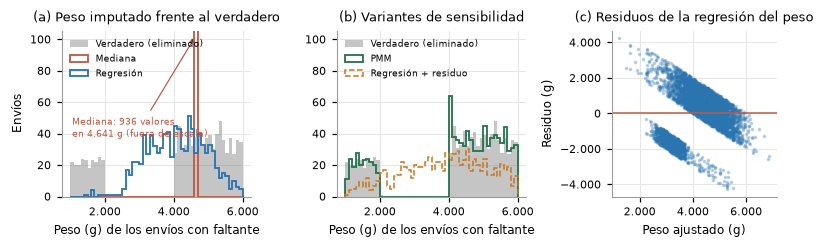

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3), gridspec_kw={"width_ratios": [1.15, 1.15, 1]})
f_peso = pd.concat([ent0, pru0])["Weight_in_gms"].isna().to_numpy()
verdad_peso = todo_true["Weight_in_gms"].to_numpy()[f_peso]
bins = np.linspace(1000, 6000, 51)
ax = axes[0]
alturas, _, _ = ax.hist(verdad_peso, bins=bins, color=C_GRIS, alpha=0.45, label="Verdadero (eliminado)")
for nombre, color in [("Mediana", C_FUERA), ("Regresión", COLORES["M1"])]:
    e, p = ESTRATEGIAS[nombre]
    ax.hist(pd.concat([e, p])["Weight_in_gms"].to_numpy()[f_peso], bins=bins, histtype="step", lw=1.2, color=color, label=nombre)
techo = 2.2 * alturas.max()
ax.set_ylim(0, techo)
ax.annotate(f"Mediana: {int(f_peso.sum())} valores\nen {es(mediana_ent['Weight_in_gms'], 0)} g (fuera de escala)",
            xy=(mediana_ent["Weight_in_gms"], techo * 0.97), xytext=(1050, techo * 0.36), fontsize=6, color=C_FUERA,
            arrowprops={"arrowstyle": "->", "color": C_FUERA, "lw": 0.8})
ax.set_xlabel("Peso (g) de los envíos con faltante"); ax.set_ylabel("Envíos"); ax.set_title("(a) Peso imputado frente al verdadero")
ax.legend(loc="upper left", fontsize=6)
ax = axes[1]
e, p = ESTRATEGIAS["PMM (sensibilidad)"]
ax.hist(verdad_peso, bins=bins, color=C_GRIS, alpha=0.45, label="Verdadero (eliminado)")
ax.hist(pd.concat([e, p])["Weight_in_gms"].to_numpy()[f_peso], bins=bins, histtype="step", lw=1.2, color=COLORES["M3"], label="PMM")
e, p = ESTRATEGIAS["Regresión + residuo (sensibilidad)"]
ax.hist(pd.concat([e, p])["Weight_in_gms"].to_numpy()[f_peso], bins=bins, histtype="step", lw=1.0, ls="--", color=COLORES["M2"], label="Regresión + residuo")
ax.set_ylim(0, techo); ax.set_xlabel("Peso (g) de los envíos con faltante"); ax.set_title("(b) Variantes de sensibilidad"); ax.legend(loc="upper left", fontsize=6)
ax = axes[2]
m = reg_imp["Weight_in_gms"]
ax.scatter(m.fittedvalues, m.resid, s=2, alpha=0.25, color=COLORES["M1"], rasterized=True)
ax.axhline(0, color=C_FUERA, lw=1)
ax.set_xlabel("Peso ajustado (g)"); ax.set_ylabel("Residuo (g)"); ax.set_title("(c) Residuos de la regresión del peso")
fig.tight_layout()
guardar_figura(fig, "s3_fig01_imputacion")
plt.show()

In [10]:
c = comparacion_imp.set_index("estrategia")
med, reg, ver = c.loc["Mediana"], c.loc["Regresión"], c.loc["Valores verdaderos (referencia)"]
pmm, res, eli = c.loc["PMM (sensibilidad)"], c.loc["Regresión + residuo (sensibilidad)"], c.loc["Eliminación"]
display(Markdown(
    f"**Comparación.** "
    f"(1) **Tamaño:** la eliminación deja {es(eli['n_entrenamiento'], 0)} envíos de entrenamiento y {es(eli['n_prueba'], 0)} de prueba "
    f"({pct(1 - eli['n_entrenamiento'] / ver['n_entrenamiento'])} menos); las imputaciones conservan los {es(ver['n_entrenamiento'], 0)} y {es(ver['n_prueba'], 0)}. "
    f"(2) **Error de imputación:** la regresión reduce el RMSE del peso de {es(med['rmse_peso'], 0)} g (mediana) a {es(reg['rmse_peso'], 0)} g "
    f"y el del costo de {es(med['rmse_costo'], 1)} a {es(reg['rmse_costo'], 1)}; las variantes estocásticas tienen más error puntual "
    f"(PMM: {es(pmm['rmse_peso'], 0)} g), el precio de reproducir la variabilidad. "
    f"(3) **Distribución:** la mediana y la regresión encogen la dispersión (razón de DE del peso {es(med['razon_de_peso'], 3)} y {es(reg['razon_de_peso'], 3)}), "
    f"y la regresión coloca un {es(reg['pct_peso_hueco_2000_3999'], 1)} % de todos los pesos (el {es(reg['pct_imputados_en_hueco'], 1)} % de los imputados) en el hueco 2.000-3.999 g, donde los datos verdaderos tienen {es(ver['pct_peso_hueco_2000_3999'], 2)} %: "
    f"predice valores medios que no existen en una variable bimodal, como anticipó S2. PMM conserva la forma (KS = {es(pmm['ks_peso'], 3)} frente a {es(reg['ks_peso'], 3)}). "
    f"(4) **Correlaciones:** la correlación costo-peso verdadera es {es(ver['rho_costo_peso'], 3)}; la mediana la atenúa a {es(med['rho_costo_peso'], 3)} y la regresión la "
    f"exagera a {es(reg['rho_costo_peso'], 3)}, porque coloca cada valor imputado sobre la recta de regresión, sin su dispersión; PMM la reproduce ({es(pmm['rho_costo_peso'], 3)}). Las correlaciones con el retraso quedan en torno a {es(ver['rho_costo_retraso'], 3)} (costo) y "
    f"{es(ver['rho_peso_retraso'], 3)} (peso) con todas las estrategias. "
    f"**Decisión:** se adopta la **imputación por regresión** para el resto del desarrollo. Tiene el menor error de imputación, conserva todos los envíos y usa la estructura de correlaciones de S1 validada en el subconjunto. "
    f"Se asumen como costos conocidos el encogimiento de varianza y los valores en el hueco del peso; la sección 3 comprueba si alguno cambia las conclusiones del modelo."
))

**Comparación.** (1) **Tamaño:** la eliminación deja 4.291 envíos de entrenamiento y 1.794 de prueba (22,0 % menos); las imputaciones conservan los 5.504 y 2.360. (2) **Error de imputación:** la regresión reduce el RMSE del peso de 1.635 g (mediana) a 1.311 g y el del costo de 47,5 a 43,0; las variantes estocásticas tienen más error puntual (PMM: 1.540 g), el precio de reproducir la variabilidad. (3) **Distribución:** la mediana y la regresión encogen la dispersión (razón de DE del peso 0,946 y 0,958), y la regresión coloca un 5,2 % de todos los pesos (el 43,6 % de los imputados) en el hueco 2.000-3.999 g, donde los datos verdaderos tienen 0,04 %: predice valores medios que no existen en una variable bimodal, como anticipó S2. PMM conserva la forma (KS = 0,003 frente a 0,029). (4) **Correlaciones:** la correlación costo-peso verdadera es −0,374; la mediana la atenúa a −0,322 y la regresión la exagera a −0,450, porque coloca cada valor imputado sobre la recta de regresión, sin su dispersión; PMM la reproduce (−0,365). Las correlaciones con el retraso quedan en torno a 0,034 (costo) y −0,023 (peso) con todas las estrategias. **Decisión:** se adopta la **imputación por regresión** para el resto del desarrollo. Tiene el menor error de imputación, conserva todos los envíos y usa la estructura de correlaciones de S1 validada en el subconjunto. Se asumen como costos conocidos el encogimiento de varianza y los valores en el hueco del peso; la sección 3 comprueba si alguno cambia las conclusiones del modelo.

## 2. Clasificación mediante regresión logística

### 2.1 Preparación de datos informada por S1

- **Dataset:** imputación por regresión (sección 1.3), con la partición de F2. Entrenamiento: 5.504 envíos; prueba: 2.360; 43,6 % fuera de plazo en ambos.
- **Variables candidatas:** las conocidas antes del despacho, es decir, costo, peso, compras previas, descuento, importancia, medio de transporte, bloque de almacén y género. Llamadas y calificación quedan fuera por posible fuga (S2, recomendación 3).
- **Valores atípicos de S1:** S1 los conservó por no ser errores de captura. En ID > 3.135 el descuento no tiene atípicos (máximo 10). Las compras previas los tienen en la cola derecha (hasta 10), pero son conteos válidos y se conservan. Su influencia se revisa en la sección 2.4.
- **Escalamiento:** las numéricas se estandarizan con la media y la desviación estándar de los **valores observados del entrenamiento**. La escala no depende de la estrategia de imputación, y los coeficientes son comparables entre modelos y entre las estrategias de la sección 3.
- **Codificación:** las categóricas usan indicadores con la categoría más frecuente o la de menor importancia como referencia.
- **Balance de clases:** 43,6 % de retrasos, casi balanceado. Aun así, las probabilidades predichas se concentran cerca de la tasa base y el umbral 0,5 deja el recall cerca de 0 (F2). Por eso, para clasificar se usa **ponderación de clases** (`class_weight="balanced"`). La inferencia (coeficientes, IC de Wald y bootstrap) usa el ajuste por máxima verosimilitud sin ponderar, como en el ejemplo del curso.

In [11]:
NUM = ["Cost_of_the_Product", "Weight_in_gms", "Prior_purchases", "Discount_offered"]
media_obs = ent0[NUM].mean()          # pandas omite los faltantes: escala de los valores observados
de_obs = ent0[NUM].std()


def matriz(d):
    X = pd.DataFrame(index=d.index)
    X[NUM] = (d[NUM].astype(float) - media_obs) / de_obs
    X["Importancia_alta"] = d["Product_importance"].eq("high").astype(float)
    X["Importancia_media"] = d["Product_importance"].eq("medium").astype(float)
    for m in ["Flight", "Road"]:
        X[f"Medio_{m}"] = d["Mode_of_Shipment"].eq(m).astype(float)
    for b in ["A", "B", "C", "D"]:
        X[f"Bloque_{b}"] = d["Warehouse_block"].eq(b).astype(float)
    X["Genero_M"] = d["Gender"].eq("M").astype(float)
    return X


GRUPOS = {"Costo": ["Cost_of_the_Product"], "Peso": ["Weight_in_gms"], "Compras previas": ["Prior_purchases"],
          "Descuento": ["Discount_offered"], "Importancia": ["Importancia_alta", "Importancia_media"],
          "Medio de transporte": ["Medio_Flight", "Medio_Road"], "Bloque de almacén": ["Bloque_A", "Bloque_B", "Bloque_C", "Bloque_D"],
          "Género": ["Genero_M"]}
ent, pru = ent_reg, pru_reg
X_ent, X_pru = matriz(ent), matriz(pru)
y_ent, y_pru = ent[OBJETIVO].to_numpy(), pru[OBJETIVO].to_numpy()

q1, q3 = np.percentile(ent0["Prior_purchases"], [25, 75])
atip_cp = int((ent0["Prior_purchases"] > q3 + 1.5 * (q3 - q1)).sum())
print(f"Entrenamiento: {len(y_ent):,} envíos ({y_ent.mean():.1%} fuera de plazo) · prueba: {len(y_pru):,} ({y_pru.mean():.1%})")
print(f"Atípicos IQR en entrenamiento: compras previas {atip_cp} (máximo {ent0['Prior_purchases'].max()}), "
      f"descuento {int((ent0['Discount_offered'] > np.percentile(ent0['Discount_offered'], 75) + 1.5 * np.subtract(*np.percentile(ent0['Discount_offered'], [75, 25]))).sum())}")
print("Referencias: importancia baja · medio Ship · bloque F · género F")
display(pd.DataFrame({"media_observada": media_obs, "de_observada": de_obs}).round(3))

Entrenamiento: 5,504 envíos (43.6% fuera de plazo) · prueba: 2,360 (43.6%)
Atípicos IQR en entrenamiento: compras previas 542 (máximo 10), descuento 0
Referencias: importancia baja · medio Ship · bloque F · género F


,media_observada,de_observada
Cost_of_the_Product,215.175,48.081
Weight_in_gms,4114.769,1589.653
Prior_purchases,3.695,1.518
Discount_offered,5.501,2.890


### 2.2 Selección de variables informada por S1 y S2: tres modelos

| Modelo | Criterio | Variables |
|---|---|---|
| **M1 · Validado por S1 y S2** | Variables con evidencia dentro de ID > 3.135 en S2 (el modelo de F2) | Importancia alta, costo, peso |
| **M2 · Stepwise por AIC** | Selección bidireccional desde el modelo vacío: en cada paso se agrega o quita el grupo de variables que más reduce el AIC; termina cuando ningún cambio lo reduce | Las que elija el algoritmo entre las 8 candidatas |
| **M3 · Reducido** | Parsimonia: solo la señal que S1 y S2 encontraron en ambos conjuntos | Importancia alta |

Las categóricas entran o salen como **grupo** (todos sus indicadores juntos). En paralelo se registra el BIC de cada paso y se ejecuta la misma selección con BIC (penalización ln n por parámetro). Así se cubren los criterios AIC y BIC del apunte de selección de variables.

In [12]:
def ajustar(cols, X=None, y=None):
    X = X_ent if X is None else X
    y = y_ent if y is None else y
    return sm.Logit(y, sm.add_constant(X[cols], has_constant="add")).fit(disp=0, maxiter=200)


def columnas(grupos):
    return [c for g in grupos for c in GRUPOS[g]]


def stepwise(criterio, X=None, y=None, registrar=False):
    sel, tray = [], []
    actual = ajustar([], X, y)
    valor = getattr(actual, criterio)
    if registrar:
        tray.append({"paso": 0, "accion": "Modelo vacío", "AIC": actual.aic, "BIC": actual.bic, "variables": "—"})
    while True:
        mejor = None
        for g in GRUPOS:
            cand = sel + [g] if g not in sel else [x for x in sel if x != g]
            m = ajustar(columnas(cand), X, y)
            v = getattr(m, criterio)
            if mejor is None or v < mejor[0]:
                mejor = (v, ("+ " if g not in sel else "− ") + g, cand, m)
        if mejor[0] >= valor - 1e-9:
            break
        valor, sel = mejor[0], mejor[2]
        if registrar:
            tray.append({"paso": len(tray), "accion": mejor[1], "AIC": mejor[3].aic, "BIC": mejor[3].bic, "variables": ", ".join(sel)})
    return sel, tray


sel_aic, tray_aic = stepwise("aic", registrar=True)
sel_bic, tray_bic = stepwise("bic", registrar=True)
trayectoria = pd.DataFrame(tray_aic)
trayectoria.insert(0, "criterio", "AIC")
trayectoria = pd.concat([trayectoria, pd.DataFrame(tray_bic).assign(criterio="BIC")], ignore_index=True)
guardar_tabla(trayectoria, "s3_tab05_trayectoria_stepwise")
with pd.option_context("display.float_format", "{:.2f}".format):
    display(trayectoria)
print("Stepwise AIC selecciona:", sel_aic)
print("Stepwise BIC selecciona:", sel_bic if sel_bic else "ninguna variable (modelo vacío)")

,criterio,paso,accion,AIC,BIC,variables
0,AIC,0,Modelo vacío,7541.36,7547.97,—
1,AIC,1,+ Costo,7535.25,7548.48,Costo
2,AIC,2,+ Importancia,7533.26,7559.72,"Costo, Importancia"
3,AIC,3,+ Descuento,7533.19,7566.25,"Costo, Importancia, Descuento"
4,BIC,0,Modelo vacío,7541.36,7547.97,—


Stepwise AIC selecciona: ['Costo', 'Importancia', 'Descuento']
Stepwise BIC selecciona: ninguna variable (modelo vacío)


In [13]:
MODELOS = {
    "M1": {"nombre": "M1 · Validado S1/S2", "cols": ["Importancia_alta", "Cost_of_the_Product", "Weight_in_gms"]},
    "M2": {"nombre": "M2 · Stepwise AIC", "cols": columnas(sel_aic)},
    "M3": {"nombre": "M3 · Reducido", "cols": ["Importancia_alta"]},
}
etiqueta = {"const": "Intercepto", "Importancia_alta": "Importancia alta", "Importancia_media": "Importancia media",
            "Cost_of_the_Product": "Costo (por DE)", "Weight_in_gms": "Peso (por DE)", "Discount_offered": "Descuento (por DE)",
            "Prior_purchases": "Compras previas (por DE)", "Medio_Flight": "Medio aéreo", "Medio_Road": "Medio terrestre",
            "Bloque_A": "Bloque A", "Bloque_B": "Bloque B", "Bloque_C": "Bloque C", "Bloque_D": "Bloque D", "Genero_M": "Género M"}
nulo = ajustar([])
filas, resumen = [], []
for k, spec in MODELOS.items():
    m = ajustar(spec["cols"])
    spec["fit"] = m
    ic = m.conf_int()
    holm = multipletests(m.pvalues[1:], method="holm")[1] if len(m.params) > 1 else []
    for j, t in enumerate(m.params.index):
        filas.append({"modelo": k, "termino": etiqueta[t], "coeficiente": m.params[t], "ee": m.bse[t], "p": m.pvalues[t],
                      "p_holm": np.nan if t == "const" else holm[j - 1], "OR": np.exp(m.params[t]),
                      "OR_inf": np.exp(ic.loc[t, 0]), "OR_sup": np.exp(ic.loc[t, 1])})
    lr = 2 * (m.llf - nulo.llf)
    resumen.append({"modelo": k, "parametros": len(m.params), "AIC": m.aic, "BIC": m.bic, "pseudo_R2_McFadden": m.prsquared,
                    "LR_vs_nulo": lr, "p_LR": stats.chi2.sf(lr, len(m.params) - 1)})
coef_modelos = guardar_tabla(pd.DataFrame(filas), "s3_tab06_coeficientes_modelos")
ajuste_modelos = guardar_tabla(pd.DataFrame(resumen), "s3_tab06b_ajuste_modelos")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(coef_modelos)
    display(ajuste_modelos)

,modelo,termino,coeficiente,ee,p,p_holm,OR,OR_inf,OR_sup
0,M1,Intercepto,-0.2741,0.0285,0.0000,NaN,0.7602,0.7190,0.8038
1,M1,Importancia alta,0.1895,0.0997,0.0574,0.1722,1.2086,0.9941,1.4696
2,M1,Costo (por DE),0.0625,0.0331,0.0592,0.1722,1.0645,0.9976,1.1359
3,M1,Peso (por DE),-0.0437,0.0331,0.1865,0.1865,0.9572,0.8972,1.0214
4,M2,Intercepto,-0.2259,0.0392,0.0000,NaN,0.7978,0.7389,0.8615
5,M2,Costo (por DE),0.0826,0.0287,0.0040,0.0162,1.0861,1.0266,1.1491
6,M2,Importancia alta,0.1207,0.1026,0.2395,0.2996,1.1283,0.9228,1.3795
7,M2,Importancia media,-0.0984,0.0570,0.0842,0.2526,0.9063,0.8105,1.0134
8,M2,Descuento (por DE),-0.0392,0.0272,0.1498,0.2996,0.9615,0.9115,1.0143
9,M3,Intercepto,-0.2707,0.0284,0.0000,NaN,0.7628,0.7215,0.8065


,modelo,parametros,AIC,BIC,pseudo_R2_McFadden,LR_vs_nulo,p_LR
0,M1,4,7534.4825,7560.9355,0.0017,12.8728,0.0049
1,M2,5,7533.1872,7566.2534,0.0021,16.1681,0.0028
2,M3,2,7540.8912,7554.1176,0.0003,2.4642,0.1165


**Selección del modelo final con validación cruzada.** Para elegir sin mirar el conjunto de prueba se usa validación cruzada estratificada de 5 particiones **sobre el entrenamiento** (apunte de selección de variables). Se aplica la **regla de un error estándar**: entre los modelos cuyo AUC medio de validación cruzada está a menos de un error estándar del mejor, se elige el más simple. El conjunto de prueba se reserva para confirmar el desempeño del modelo elegido (sección 2.5).

In [14]:
skf = StratifiedKFold(K_CV, shuffle=True, random_state=SEED)
pliegues = list(skf.split(X_ent, y_ent))
cv = {}
for k, spec in MODELOS.items():
    aucs = []
    for a, b in pliegues:
        m = ajustar(spec["cols"], X_ent.iloc[a], y_ent[a])
        aucs.append(roc_auc_score(y_ent[b], m.predict(sm.add_constant(X_ent.iloc[b][spec["cols"]], has_constant="add"))))
    cv[k] = np.array(aucs)
seleccion_cv = pd.DataFrame({"modelo": list(cv), "parametros": [len(MODELOS[k]["fit"].params) for k in cv],
                             "cv_auc_media": [cv[k].mean() for k in cv], "cv_auc_de": [cv[k].std(ddof=1) for k in cv],
                             "cv_auc_ee": [cv[k].std(ddof=1) / np.sqrt(K_CV) for k in cv]})
mejor = seleccion_cv.loc[seleccion_cv["cv_auc_media"].idxmax()]
umbral_1ee = mejor["cv_auc_media"] - mejor["cv_auc_ee"]
seleccion_cv["dentro_de_1EE"] = seleccion_cv["cv_auc_media"] >= umbral_1ee
FINAL = seleccion_cv.loc[seleccion_cv["dentro_de_1EE"]].sort_values(["parametros", "cv_auc_media"], ascending=[True, False]).iloc[0]["modelo"]
seleccion_cv["final"] = seleccion_cv["modelo"].eq(FINAL)
seleccion_cv = seleccion_cv.merge(ajuste_modelos[["modelo", "AIC", "BIC"]], on="modelo")
guardar_tabla(seleccion_cv, "s3_tab07_seleccion_cv")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(seleccion_cv)
print(f"Mejor AUC de validación cruzada: {mejor['modelo']} ({mejor['cv_auc_media']:.4f}); umbral de 1 EE = {umbral_1ee:.4f} → modelo final: {FINAL}")

,modelo,parametros,cv_auc_media,cv_auc_de,cv_auc_ee,dentro_de_1EE,final,AIC,BIC
0,M1,4,0.5249,0.0071,0.0032,True,True,7534.4825,7560.9355
1,M2,5,0.5262,0.0187,0.0084,True,False,7533.1872,7566.2534
2,M3,2,0.5059,0.0039,0.0017,False,False,7540.8912,7554.1176


Mejor AUC de validación cruzada: M2 (0.5262); umbral de 1 EE = 0.5178 → modelo final: M1


In [15]:
cm_ = coef_modelos.set_index(["modelo", "termino"])
s_ = seleccion_cv.set_index("modelo")
a_ = ajuste_modelos.set_index("modelo")
or_txt = lambda k, t: f"{es(cm_.loc[(k, t), 'OR'], 3)} [{es(cm_.loc[(k, t), 'OR_inf'], 3)}; {es(cm_.loc[(k, t), 'OR_sup'], 3)}]"
paso_desc = trayectoria.query("criterio == 'AIC'")
delta_ultimo = paso_desc["AIC"].iloc[-2] - paso_desc["AIC"].iloc[-1]
display(Markdown(
    f"**Lectura de los tres modelos.** "
    f"**M1** reproduce F2 sobre los datos imputados por regresión: importancia alta OR = {or_txt('M1', 'Importancia alta')}, "
    f"costo OR = {or_txt('M1', 'Costo (por DE)')} y peso OR = {or_txt('M1', 'Peso (por DE)')}; ningún término resiste Holm. "
    f"**M2** (stepwise AIC) elige {', '.join(sel_aic).lower()}. El último paso reduce el AIC en solo {es(delta_ultimo, 2)} puntos, muy por debajo "
    f"de las 2 unidades que suelen considerarse evidencia de mejora: el algoritmo agrega variables cuya contribución no se distingue del ruido. "
    f"El descuento entra con OR = {or_txt('M2', 'Descuento (por DE)') if ('M2', 'Descuento (por DE)') in cm_.index else '—'}, pese a que S2 mostró que su correlación con el retraso es nula en ID > 3.135. "
    f"**BIC** no incorpora ninguna variable: ninguna compensa la penalización ln(n) = {es(np.log(len(y_ent)), 2)} por parámetro. "
    f"**M3** conserva la única señal validada en ambos conjuntos (OR = {or_txt('M3', 'Importancia alta')}). "
    f"Los tres modelos explican una fracción mínima de la verosimilitud (pseudo-R² de McFadden entre {es(a_['pseudo_R2_McFadden'].min(), 4)} y {es(a_['pseudo_R2_McFadden'].max(), 4)}). "
    f"**Selección:** el mejor AUC de validación cruzada es el de {mejor['modelo']} ({es(mejor['cv_auc_media'], 3)}; error estándar {es(mejor['cv_auc_ee'], 3)}). "
    f"M1 queda dentro de un error estándar ({es(s_.loc['M1', 'cv_auc_media'], 3)}) con menos parámetros y M3 queda fuera ({es(s_.loc['M3', 'cv_auc_media'], 3)}). "
    f"El modelo final es **{FINAL}**, el modelo validado por S1 y S2."
))

**Lectura de los tres modelos.** **M1** reproduce F2 sobre los datos imputados por regresión: importancia alta OR = 1,209 [0,994; 1,470], costo OR = 1,065 [0,998; 1,136] y peso OR = 0,957 [0,897; 1,021]; ningún término resiste Holm. **M2** (stepwise AIC) elige costo, importancia, descuento. El último paso reduce el AIC en solo 0,08 puntos, muy por debajo de las 2 unidades que suelen considerarse evidencia de mejora: el algoritmo agrega variables cuya contribución no se distingue del ruido. El descuento entra con OR = 0,962 [0,912; 1,014], pese a que S2 mostró que su correlación con el retraso es nula en ID > 3.135. **BIC** no incorpora ninguna variable: ninguna compensa la penalización ln(n) = 8,61 por parámetro. **M3** conserva la única señal validada en ambos conjuntos (OR = 1,168 [0,962; 1,417]). Los tres modelos explican una fracción mínima de la verosimilitud (pseudo-R² de McFadden entre 0,0003 y 0,0021). **Selección:** el mejor AUC de validación cruzada es el de M2 (0,526; error estándar 0,008). M1 queda dentro de un error estándar (0,525) con menos parámetros y M3 queda fuera (0,506). El modelo final es **M1**, el modelo validado por S1 y S2.

### 2.3 Evaluación de estabilidad mediante bootstrap

Como en S2, se aplica **bootstrap no paramétrico con 10.000 remuestras** al modelo final: se remuestrean los envíos del entrenamiento con reemplazo y se reajusta la regresión logística en cada remuestra.

- **Intervalos:** para cada coeficiente se calculan el IC **percentil** y el **BCa** al 95 %, con el sesgo z₀ de la distribución bootstrap y la aceleración *a* estimada por jackknife sobre los 5.504 envíos. Se comparan con el IC tradicional de Wald.
- **Odds ratios:** sus IC son el exponencial de los IC de los coeficientes, porque ambos métodos son invariantes ante transformaciones monótonas.
- **Parámetro inestable:** aquel cuyo IC bootstrap incluye el 0 (OR = 1), o cuyo signo cambia en una fracción apreciable de las remuestras.

S2 recomendó BCa con B ≥ 10.000 para los coeficientes de la logística (recomendación 7).

In [16]:
cols_fin = MODELOS[FINAL]["cols"]
fit_fin = MODELOS[FINAL]["fit"]
X_fin = sm.add_constant(X_ent[cols_fin], has_constant="add").to_numpy()
theta = fit_fin.params.to_numpy()
n_ent, k_par = X_fin.shape
rng = np.random.default_rng(SEED)
boot = np.empty((B_BOOT, k_par))
fallos = 0
t = time.time()
for b in range(B_BOOT):
    idx = rng.integers(0, n_ent, n_ent)
    r = sm.Logit(y_ent[idx], X_fin[idx]).fit(disp=0, start_params=theta, maxiter=100)
    if not r.mle_retvals["converged"]:
        fallos += 1
    boot[b] = r.params
jack = np.empty((n_ent, k_par))
for i in range(n_ent):
    keep = np.ones(n_ent, bool); keep[i] = False
    jack[i] = sm.Logit(y_ent[keep], X_fin[keep]).fit(disp=0, start_params=theta, maxiter=100).params
print(f"{B_BOOT:,} remuestras y {n_ent:,} réplicas jackknife en {time.time() - t:.0f} s · remuestras sin convergencia: {fallos}")


def ic_bca(dist, est, jk, alfa=0.05):
    prop = np.mean(dist < est) + 0.5 * np.mean(dist == est)
    z0 = stats.norm.ppf(prop)
    d = jk.mean() - jk
    a = np.sum(d ** 3) / (6 * np.sum(d ** 2) ** 1.5)
    zq = stats.norm.ppf([alfa / 2, 1 - alfa / 2])
    q = stats.norm.cdf(z0 + (z0 + zq) / (1 - a * (z0 + zq)))
    return np.quantile(dist, q), z0, a


ic_w = fit_fin.conf_int().to_numpy()
filas = []
for j, tname in enumerate(fit_fin.params.index):
    pi = np.percentile(boot[:, j], [2.5, 97.5])
    (bi, bs), z0, a = ic_bca(boot[:, j], theta[j], jack[:, j])
    mismo_signo = np.mean(np.sign(boot[:, j]) == np.sign(theta[j]))
    inestable = (bi <= 0 <= bs) and tname != "const"
    filas.append({"termino": etiqueta[tname], "coeficiente": theta[j], "wald_inf": ic_w[j, 0], "wald_sup": ic_w[j, 1],
                  "perc_inf": pi[0], "perc_sup": pi[1], "bca_inf": bi, "bca_sup": bs, "z0": z0, "a": a,
                  "ee_wald": fit_fin.bse.iloc[j], "ee_boot": boot[:, j].std(ddof=1),
                  "razon_ee_boot_wald": boot[:, j].std(ddof=1) / fit_fin.bse.iloc[j],
                  "pct_mismo_signo": 100 * mismo_signo, "OR": np.exp(theta[j]), "OR_bca_inf": np.exp(bi), "OR_bca_sup": np.exp(bs),
                  "OR_wald_inf": np.exp(ic_w[j, 0]), "OR_wald_sup": np.exp(ic_w[j, 1]),
                  "estado": "—" if tname == "const" else ("Inestable: IC incluye OR = 1" if inestable else "Estable")})
boot_tab = guardar_tabla(pd.DataFrame(filas), "s3_tab08_bootstrap_coeficientes")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(boot_tab)

10,000 remuestras y 5,504 réplicas jackknife en 28 s · remuestras sin convergencia: 0


,termino,coeficiente,wald_inf,wald_sup,perc_inf,perc_sup,bca_inf,bca_sup,z0,a,ee_wald,ee_boot,razon_ee_boot_wald,pct_mismo_signo,OR,OR_bca_inf,OR_bca_sup,OR_wald_inf,OR_wald_sup,estado
0,Intercepto,-0.2741,-0.3299,-0.2184,-0.3300,-0.2192,-0.3297,-0.2188,0.0030,0.0007,0.0285,0.0283,0.9946,100.0000,0.7602,0.7191,0.8034,0.7190,0.8038,—
1,Importancia alta,0.1895,-0.0060,0.3850,-0.0098,0.3809,-0.0099,0.3805,-0.0025,0.0007,0.0997,0.1001,1.0037,96.8100,1.2086,0.9902,1.4631,0.9941,1.4696,Inestable: IC incluye OR = 1
2,Costo (por DE),0.0625,-0.0024,0.1274,-0.0040,0.1285,-0.0039,0.1285,0.0033,-0.0005,0.0331,0.0337,1.0161,96.7300,1.0645,0.9961,1.1371,0.9976,1.1359,Inestable: IC incluye OR = 1
3,Peso (por DE),-0.0437,-0.1085,0.0211,-0.1081,0.0212,-0.1078,0.0216,0.0078,-0.0000,0.0331,0.0334,1.0089,90.5200,0.9572,0.8978,1.0218,0.8972,1.0214,Inestable: IC incluye OR = 1


**Estabilidad de la selección.** La rúbrica pide identificar parámetros inestables. En un modelo elegido por un algoritmo, la inestabilidad también puede estar en **qué variables entran**. Se repite el stepwise por AIC en 1.000 remuestras bootstrap del entrenamiento y se cuenta con qué frecuencia selecciona cada variable. Una variable seleccionada en pocas remuestras indica que su inclusión en M2 depende de la muestra concreta.

In [17]:
rng = np.random.default_rng(SEED + 1)
conteo = {g: 0 for g in GRUPOS}
n_vars = []
t = time.time()
for b in range(B_SEL):
    idx = rng.integers(0, n_ent, n_ent)
    sel_b, _ = stepwise("aic", X_ent.iloc[idx].reset_index(drop=True), y_ent[idx])
    for g in sel_b:
        conteo[g] += 1
    n_vars.append(len(sel_b))
frec_sel = guardar_tabla(pd.DataFrame({"variable": list(conteo), "frecuencia_seleccion_pct": [100 * conteo[g] / B_SEL for g in conteo],
                                       "en_M2": [g in sel_aic for g in conteo], "en_M1": [g in ("Costo", "Peso") for g in conteo]})
                         .sort_values("frecuencia_seleccion_pct", ascending=False), "s3_tab09_frecuencia_seleccion")
display(frec_sel)
print(f"{B_SEL:,} stepwise bootstrap en {time.time() - t:.0f} s · variables seleccionadas por remuestra: mediana {np.median(n_vars):.0f}, "
      f"rango {min(n_vars)}-{max(n_vars)} · remuestras con modelo vacío: {np.mean(np.array(n_vars) == 0):.1%}")

,variable,frecuencia_seleccion_pct,en_M2,en_M1
4,Importancia,75.6,True,False
0,Costo,73.5,True,True
3,Descuento,52.4,True,False
7,Género,49.9,False,False
1,Peso,46.7,False,True
2,Compras previas,32.2,False,False
5,Medio de transporte,25.5,False,False
6,Bloque de almacén,14.0,False,False


1,000 stepwise bootstrap en 101 s · variables seleccionadas por remuestra: mediana 4, rango 0-8 · remuestras con modelo vacío: 0.3%


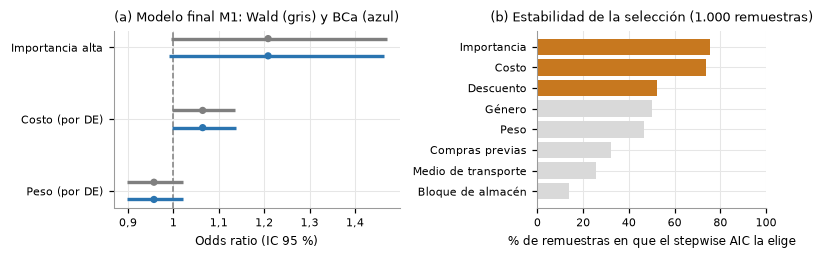

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
bt = boot_tab.loc[boot_tab["termino"].ne("Intercepto")].reset_index(drop=True)
yy = np.arange(len(bt))[::-1]
ax.axvline(1, color=C_GRIS, ls="--", lw=1)
for i, r in bt.iterrows():
    ax.plot([r["OR_wald_inf"], r["OR_wald_sup"]], [yy[i] + 0.12] * 2, color=C_GRIS, lw=2.2, solid_capstyle="butt")
    ax.plot([r["OR_bca_inf"], r["OR_bca_sup"]], [yy[i] - 0.12] * 2, color=COLORES["M1"], lw=2.2, solid_capstyle="butt")
    ax.scatter([r["OR"]] * 2, [yy[i] + 0.12, yy[i] - 0.12], color=[C_GRIS, COLORES["M1"]], s=14, zorder=3)
ax.set_yticks(yy, bt["termino"]); ax.set_xlabel("Odds ratio (IC 95 %)")
ax.set_title(f"(a) Modelo final {FINAL}: Wald (gris) y BCa (azul)")
ax = axes[1]
fs = frec_sel.sort_values("frecuencia_seleccion_pct")
ax.barh(fs["variable"], fs["frecuencia_seleccion_pct"], color=[COLORES["M2"] if e else "#D9D9D9" for e in fs["en_M2"]])
ax.set_xlabel("% de remuestras en que el stepwise AIC la elige"); ax.set_xlim(0, 100)
ax.set_title(f"(b) Estabilidad de la selección ({B_SEL:,} remuestras)".replace(",", "."))
fig.tight_layout()
guardar_figura(fig, "s3_fig02_bootstrap")
plt.show()

In [19]:
b_ = boot_tab.set_index("termino")
inest = b_.loc[b_["estado"].str.startswith("Inestable")].index.tolist()
corto = lambda t: t.replace(" (por DE)", "").lower()
est = b_.loc[b_["estado"].eq("Estable")].index.tolist()
f_ = frec_sel.set_index("variable")["frecuencia_seleccion_pct"]
display(Markdown(
    f"**Lectura.** Los IC bootstrap coinciden con los de Wald: la razón entre errores estándar bootstrap y de Wald va de "
    f"{es(b_['razon_ee_boot_wald'].min(), 3)} a {es(b_['razon_ee_boot_wald'].max(), 3)}, y z₀ y *a* son cercanos a 0 "
    f"(|z₀| ≤ {es(b_['z0'].abs().max(), 3)}; |a| ≤ {es(b_['a'].abs().max(), 4)}). Con 5.504 envíos y sin separación, la normalidad asintótica del estimador de máxima "
    f"verosimilitud se sostiene, como S2 anticipó para muestras grandes. **Parámetros inestables:** "
    f"{'los tres coeficientes' if len(inest) == 3 else ', '.join(corto(t) for t in inest) if inest else 'ninguno'}. "
    f"Sus IC BCa incluyen OR = 1: " + "; ".join(f"{corto(t)} OR = {es(b_.loc[t, 'OR'], 3)} [{es(b_.loc[t, 'OR_bca_inf'], 3)}; {es(b_.loc[t, 'OR_bca_sup'], 3)}], mismo signo en el {es(b_.loc[t, 'pct_mismo_signo'], 1)} % de las remuestras" for t in inest) + ". "
    f"{'**Estable:** ' + ', '.join(corto(t) for t in est) + '. ' if est else ''}"
    f"**Selección:** el stepwise elige el costo en el {es(f_['Costo'], 1)} % de las remuestras y la importancia en el {es(f_['Importancia'], 1)} %, "
    f"pero el descuento solo en el {es(f_['Descuento'], 1)} %: su presencia en M2 es circunstancial, lo que confirma que el modelo final no debía basarse en él. "
    f"El bootstrap no revela problemas numéricos: los intervalos son simétricos y concuerdan con Wald. Lo que muestra es que los tres efectos son "
    f"**pequeños y compatibles con cero**, coherente con la potencia de 49 % estimada en S2."
))

**Lectura.** Los IC bootstrap coinciden con los de Wald: la razón entre errores estándar bootstrap y de Wald va de 0,995 a 1,016, y z₀ y *a* son cercanos a 0 (|z₀| ≤ 0,008; |a| ≤ 0,0007). Con 5.504 envíos y sin separación, la normalidad asintótica del estimador de máxima verosimilitud se sostiene, como S2 anticipó para muestras grandes. **Parámetros inestables:** los tres coeficientes. Sus IC BCa incluyen OR = 1: importancia alta OR = 1,209 [0,990; 1,463], mismo signo en el 96,8 % de las remuestras; costo OR = 1,065 [0,996; 1,137], mismo signo en el 96,7 % de las remuestras; peso OR = 0,957 [0,898; 1,022], mismo signo en el 90,5 % de las remuestras. **Selección:** el stepwise elige el costo en el 73,5 % de las remuestras y la importancia en el 75,6 %, pero el descuento solo en el 52,4 %: su presencia en M2 es circunstancial, lo que confirma que el modelo final no debía basarse en él. El bootstrap no revela problemas numéricos: los intervalos son simétricos y concuerdan con Wald. Lo que muestra es que los tres efectos son **pequeños y compatibles con cero**, coherente con la potencia de 49 % estimada en S2.

### 2.4 Diagnóstico de supuestos

| Supuesto | Diagnóstico (apuntes de regresión logística y de diagnóstico) |
|---|---|
| Multicolinealidad | VIF de los predictores de M1 y M2 |
| Linealidad en el logit | Prueba de Box-Tidwell: se agrega x·ln(x) para costo y peso (positivos) y se contrasta su coeficiente |
| Observaciones influyentes | Distancia de Cook (umbral 4/n) y apalancamiento; reajuste sin las observaciones sobre el umbral |
| Residuos y calibración | Residuos de Pearson, prueba de Hosmer-Lemeshow con deciles de probabilidad y gráfico de calibración |

In [20]:
filas = []
for k in ("M1", "M2"):
    Xv = sm.add_constant(X_ent[MODELOS[k]["cols"]], has_constant="add").to_numpy()
    for i, c in enumerate(MODELOS[k]["cols"], start=1):
        filas.append({"modelo": k, "predictor": etiqueta[c], "VIF": variance_inflation_factor(Xv, i)})
vif = guardar_tabla(pd.DataFrame(filas), "s3_tab10_vif")
display(vif.round(3))

# Box-Tidwell sobre las variables en escala original (positivas).
d_bt = pd.DataFrame({"Importancia_alta": X_ent["Importancia_alta"]})
for v in ["Cost_of_the_Product", "Weight_in_gms"]:
    d_bt[v] = ent[v].to_numpy()
    d_bt[v + "_xlnx"] = ent[v].to_numpy() * np.log(ent[v].to_numpy())
m_bt = sm.Logit(y_ent, sm.add_constant(d_bt)).fit(disp=0)
box_tidwell = pd.DataFrame({"variable": ["Costo", "Peso"],
                            "coef_xlnx": m_bt.params[["Cost_of_the_Product_xlnx", "Weight_in_gms_xlnx"]].to_numpy(),
                            "p": m_bt.pvalues[["Cost_of_the_Product_xlnx", "Weight_in_gms_xlnx"]].to_numpy()})
guardar_tabla(box_tidwell, "s3_tab11_box_tidwell")
display(box_tidwell.round(4))

,modelo,predictor,VIF
0,M1,Importancia alta,1.021
1,M1,Costo (por DE),1.337
2,M1,Peso (por DE),1.360
3,M2,Costo (por DE),1.005
4,M2,Importancia alta,1.080
5,M2,Importancia media,1.076
6,M2,Descuento (por DE),1.001


,variable,coef_xlnx,p
0,Costo,0.0039,0.4304
1,Peso,-0.0002,0.1216


In [21]:
glm = sm.GLM(y_ent, sm.add_constant(X_ent[cols_fin], has_constant="add"), family=sm.families.Binomial()).fit()
infl = glm.get_influence()
cook = infl.cooks_distance[0]
apal = infl.hat_matrix_diag
pearson = glm.resid_pearson
umbral_cook = 4 / n_ent
sobre = cook > umbral_cook
m_sin = ajustar(cols_fin, X_ent.loc[~sobre], y_ent[~sobre])
cambio_coef = (m_sin.params - fit_fin.params) / fit_fin.bse
pct_alta_infl = 100 * X_ent.loc[sobre, "Importancia_alta"].mean()
tasa_infl = y_ent[sobre].mean()

p_fin = fit_fin.predict(sm.add_constant(X_ent[cols_fin], has_constant="add")).to_numpy()
deciles = pd.qcut(p_fin, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"decil": deciles, "p": p_fin, "y": y_ent}).groupby("decil").agg(n=("y", "size"), p_media=("p", "mean"), observado=("y", "mean"), esperados=("p", "sum"), observados=("y", "sum"))
hl = float((((calib["observados"] - calib["esperados"]) ** 2) / (calib["esperados"] * (1 - calib["p_media"]))).sum())
gl_hl = len(calib) - 2
p_hl = stats.chi2.sf(hl, gl_hl)

influencia = guardar_tabla(pd.DataFrame([
    {"diagnostico": "Distancia de Cook máxima", "valor": cook.max()},
    {"diagnostico": "Umbral 4/n", "valor": umbral_cook},
    {"diagnostico": "Observaciones sobre el umbral", "valor": int(sobre.sum())},
    {"diagnostico": "Apalancamiento máximo (promedio = p/n)", "valor": apal.max()},
    {"diagnostico": "Residuos de Pearson |r| > 2 (%)", "valor": 100 * np.mean(np.abs(pearson) > 2)},
    {"diagnostico": "Máximo cambio de coeficiente sin esas observaciones (en EE)", "valor": float(cambio_coef.abs().max())},
    {"diagnostico": "Influyentes de importancia alta (%)", "valor": pct_alta_infl},
    {"diagnostico": "Tasa de retraso de los influyentes", "valor": tasa_infl},
    {"diagnostico": "Importancia alta en el entrenamiento (%)", "valor": 100 * X_ent["Importancia_alta"].mean()},
    {"diagnostico": "Hosmer-Lemeshow (estadístico)", "valor": hl},
    {"diagnostico": "Hosmer-Lemeshow (p)", "valor": p_hl},
]), "s3_tab12_influencia_calibracion")
display(influencia.round(5))
guardar_tabla(calib.reset_index(), "s3_tab12b_calibracion_deciles")
print("Cambio de cada coeficiente al excluir las observaciones influyentes (en errores estándar):", cambio_coef.round(3).to_dict())

,diagnostico,valor
0,Distancia de Cook máxima,0.00123
1,Umbral 4/n,0.00073
2,Observaciones sobre el umbral,75.00000
3,Apalancamiento máximo (promedio = p/n),0.00381
4,Residuos de Pearson |r| > 2 (%),0.00000
5,Máximo cambio de coeficiente sin esas observac...,1.94742
6,Influyentes de importancia alta (%),88.00000
7,Tasa de retraso de los influyentes,0.78667
8,Importancia alta en el entrenamiento (%),8.17587
9,Hosmer-Lemeshow (estadístico),6.27099


Cambio de cada coeficiente al excluir las observaciones influyentes (en errores estándar): {'const': -0.172, 'Importancia_alta': -1.947, 'Cost_of_the_Product': 1.089, 'Weight_in_gms': 0.364}


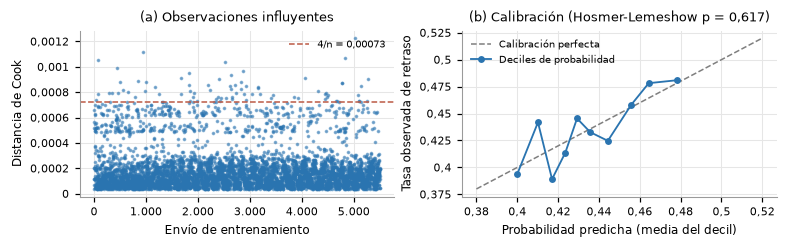

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.3))
ax = axes[0]
ax.scatter(np.arange(n_ent), cook, s=2, color=COLORES["M1"], alpha=0.5, rasterized=True)
ax.axhline(umbral_cook, color=C_FUERA, ls="--", lw=1, label=f"4/n = {es(umbral_cook, 5)}")
ax.set_xlabel("Envío de entrenamiento"); ax.set_ylabel("Distancia de Cook"); ax.set_title("(a) Observaciones influyentes")
ax.legend(loc="upper right")
ax = axes[1]
ax.plot([0.38, 0.52], [0.38, 0.52], color=C_GRIS, ls="--", lw=1, label="Calibración perfecta")
ax.plot(calib["p_media"], calib["observado"], "o-", color=COLORES["M1"], ms=3.5, label="Deciles de probabilidad")
ax.set_xlabel("Probabilidad predicha (media del decil)"); ax.set_ylabel("Tasa observada de retraso")
ax.set_title(f"(b) Calibración (Hosmer-Lemeshow p = {es(p_hl, 3)})"); ax.legend(loc="upper left")
fig.tight_layout()
guardar_figura(fig, "s3_fig03_diagnostico")
plt.show()

In [23]:
v_ = vif.set_index(["modelo", "predictor"])["VIF"]
inf_ = influencia.set_index("diagnostico")["valor"]
display(Markdown(
    f"**Lectura.** (1) **Multicolinealidad:** VIF máximo {es(v_.loc['M1'].max(), 2)} en M1 y {es(v_.loc['M2'].max(), 2)} en M2, lejos del umbral de 5. "
    f"La correlación entre costo y peso (−0,37 en ID > 3.135) no infla las varianzas. "
    f"(2) **Linealidad en el logit:** Box-Tidwell no la rechaza para el costo (p = {es(box_tidwell.loc[0, 'p'], 3)}) ni para el peso (p = {es(box_tidwell.loc[1, 'p'], 3)}). "
    f"(3) **Influencia:** {int(inf_['Observaciones sobre el umbral'])} envíos superan 4/n, pero la distancia de Cook máxima es {es(inf_['Distancia de Cook máxima'], 4)}, "
    f"muy lejos de 1: ningún envío individual domina el ajuste. Como grupo, en cambio, sí pesan: el {es(inf_['Influyentes de importancia alta (%)'], 1)} % son de importancia alta "
    f"(frente a {es(inf_['Importancia alta en el entrenamiento (%)'], 1)} % del entrenamiento) y su tasa de retraso es {pct(inf_['Tasa de retraso de los influyentes'])}. "
    f"Excluirlos mueve el coeficiente de la importancia alta {es(cambio_coef['Importancia_alta'], 2)} errores estándar, y los demás como máximo "
    f"{es(cambio_coef.drop(['const', 'Importancia_alta']).abs().max(), 2)}. La estimación de la importancia alta descansa en una categoría pequeña, otra razón de su inestabilidad. "
    f"(4) **Residuos y calibración:** el {es(inf_['Residuos de Pearson |r| > 2 (%)'], 1)} % de los residuos de Pearson supera 2 en valor absoluto "
    f"y Hosmer-Lemeshow no rechaza el ajuste (p = {es(p_hl, 3)}). El modelo está bien calibrado, pero sus probabilidades apenas se separan de la tasa base: "
    f"van de {es(calib['p_media'].min(), 3)} a {es(calib['p_media'].max(), 3)} entre el primer y el último decil. Los supuestos se cumplen, pero el modelo es "
    f"correcto y poco informativo a la vez."
))

**Lectura.** (1) **Multicolinealidad:** VIF máximo 1,36 en M1 y 1,08 en M2, lejos del umbral de 5. La correlación entre costo y peso (−0,37 en ID > 3.135) no infla las varianzas. (2) **Linealidad en el logit:** Box-Tidwell no la rechaza para el costo (p = 0,430) ni para el peso (p = 0,122). (3) **Influencia:** 75 envíos superan 4/n, pero la distancia de Cook máxima es 0,0012, muy lejos de 1: ningún envío individual domina el ajuste. Como grupo, en cambio, sí pesan: el 88,0 % son de importancia alta (frente a 8,2 % del entrenamiento) y su tasa de retraso es 78,7 %. Excluirlos mueve el coeficiente de la importancia alta −1,95 errores estándar, y los demás como máximo 1,09. La estimación de la importancia alta descansa en una categoría pequeña, otra razón de su inestabilidad. (4) **Residuos y calibración:** el 0,0 % de los residuos de Pearson supera 2 en valor absoluto y Hosmer-Lemeshow no rechaza el ajuste (p = 0,617). El modelo está bien calibrado, pero sus probabilidades apenas se separan de la tasa base: van de 0,400 a 0,478 entre el primer y el último decil. Los supuestos se cumplen, pero el modelo es correcto y poco informativo a la vez.

### 2.5 Evaluación de desempeño predictivo

Para los tres modelos se informan las matrices de confusión de entrenamiento y prueba, accuracy, precision, recall, F1 y especificidad, con el clasificador **ponderado por clase**, y el AUC de entrenamiento y de prueba. Para el AUC de prueba se agregan su IC bootstrap (10.000 remuestras) y una prueba de permutación (10.000 permutaciones de las etiquetas; Ojala y Garriga, 2010) que contrasta si supera el azar. La línea base es la regla de la clase mayoritaria.

In [24]:
def auc_rangos(rangos, y):
    n1 = y.sum(axis=-1)
    return ((rangos * y).sum(axis=-1) - n1 * (n1 + 1) / 2) / (n1 * (y.shape[-1] - n1))


def inferencia_auc(y, p, semilla):
    rng = np.random.default_rng(semilla)
    obs = roc_auc_score(y, p)
    rangos = stats.rankdata(p)
    perm = np.empty(B_PERM)
    for ini in range(0, B_PERM, 500):
        fin = min(ini + 500, B_PERM)
        perm[ini:fin] = auc_rangos(rangos, np.array([rng.permutation(y) for _ in range(fin - ini)]))
    boot = np.empty(B_BOOT)
    for b in range(B_BOOT):
        idx = rng.integers(0, len(y), len(y))
        boot[b] = roc_auc_score(y[idx], p[idx])
    return obs, np.percentile(boot, [2.5, 97.5]), (np.sum(perm >= obs) + 1) / (B_PERM + 1), perm


filas, matrices, probas = [], [], {}
for k, spec in MODELOS.items():
    cols = spec["cols"]
    p_ent_k = spec["fit"].predict(sm.add_constant(X_ent[cols], has_constant="add")).to_numpy()
    p_pru_k = spec["fit"].predict(sm.add_constant(X_pru[cols], has_constant="add")).to_numpy()
    probas[k] = p_pru_k
    clf = LogisticRegression(C=np.inf, class_weight="balanced", max_iter=2000).fit(X_ent[cols], y_ent)
    auc_p, ic_p, p_perm, _ = inferencia_auc(y_pru, p_pru_k, SEED)
    fila = {"modelo": k, "cv_auc": cv[k].mean(), "auc_entrenamiento": roc_auc_score(y_ent, p_ent_k), "auc_prueba": auc_p,
            "auc_ic_inf": ic_p[0], "auc_ic_sup": ic_p[1], "p_permutacion": p_perm}
    for nombre, X_, y_ in [("entrenamiento", X_ent, y_ent), ("prueba", X_pru, y_pru)]:
        yh = clf.predict(X_[cols])
        tn, fp, fn, tp = confusion_matrix(y_, yh, labels=[0, 1]).ravel()
        matrices.append({"modelo": k, "conjunto": nombre, "VN": tn, "FP": fp, "FN": fn, "VP": tp})
        fila.update({f"accuracy_{nombre}": accuracy_score(y_, yh), f"precision_{nombre}": precision_score(y_, yh, zero_division=0),
                     f"recall_{nombre}": recall_score(y_, yh), f"f1_{nombre}": f1_score(y_, yh), f"especificidad_{nombre}": tn / (tn + fp)})
    filas.append(fila)
filas.append({"modelo": "Línea base", "accuracy_entrenamiento": 1 - y_ent.mean(), "accuracy_prueba": 1 - y_pru.mean(),
              "recall_entrenamiento": 0.0, "recall_prueba": 0.0, "auc_prueba": 0.5, "especificidad_prueba": 1.0})
desempeno = guardar_tabla(pd.DataFrame(filas), "s3_tab13_desempeno_modelos")
matrices = guardar_tabla(pd.DataFrame(matrices), "s3_tab14_matrices_confusion")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(desempeno.set_index("modelo").T)
    display(matrices)

modelo,M1,M2,M3,Línea base
cv_auc,0.5249,0.5262,0.5059,NaN
auc_entrenamiento,0.5285,0.5303,0.5059,NaN
auc_prueba,0.5153,0.5074,0.5079,0.5000
auc_ic_inf,0.4922,0.4840,0.4969,NaN
auc_ic_sup,0.5392,0.5308,0.5191,NaN
p_permutacion,0.1040,0.2741,0.0645,NaN
accuracy_entrenamiento,0.5276,0.5231,0.5594,0.5641
precision_entrenamiento,0.4592,0.4593,0.4711,NaN
recall_entrenamiento,0.4714,0.5315,0.0884,0.0000
f1_entrenamiento,0.4652,0.4928,0.1488,NaN


,modelo,conjunto,VN,FP,FN,VP
0,M1,entrenamiento,1773,1332,1268,1131
1,M1,prueba,756,575,552,477
2,M2,entrenamiento,1604,1501,1124,1275
3,M2,prueba,664,667,494,535
4,M3,entrenamiento,2867,238,2187,212
5,M3,prueba,1237,94,940,89


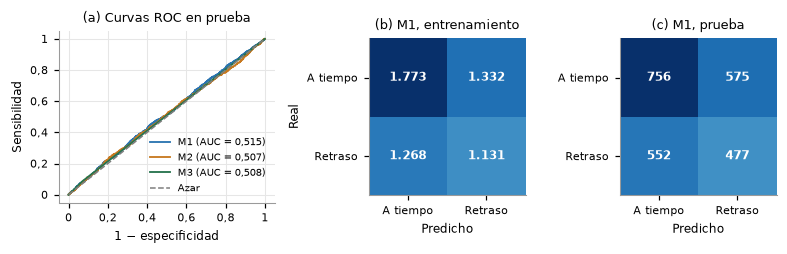

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.35), gridspec_kw={"width_ratios": [1.1, 0.8, 0.8]})
ax = axes[0]
for k in MODELOS:
    fpr, tpr, _ = roc_curve(y_pru, probas[k])
    ax.plot(fpr, tpr, color=COLORES[k], lw=1.2, label=f"{k} (AUC = {es(desempeno.set_index('modelo').loc[k, 'auc_prueba'], 3)})")
ax.plot([0, 1], [0, 1], color=C_GRIS, ls="--", lw=1, label="Azar")
ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad"); ax.set_title("(a) Curvas ROC en prueba"); ax.legend(loc="lower right")
mf = matrices.set_index(["modelo", "conjunto"])
for ax, nombre in zip(axes[1:], ["entrenamiento", "prueba"]):
    r = mf.loc[(FINAL, nombre)]
    cmx = np.array([[r["VN"], r["FP"]], [r["FN"], r["VP"]]])
    ax.imshow(cmx, cmap="Blues", vmin=0, vmax=cmx.max())
    for (i, j), v in np.ndenumerate(cmx):
        ax.text(j, i, f"{v:,}".replace(",", "."), ha="center", va="center", color="white" if v > 0.6 * cmx.max() else "black", fontsize=8, fontweight="bold")
    ax.set_xticks([0, 1], ["A tiempo", "Retraso"]); ax.set_yticks([0, 1], ["A tiempo", "Retraso"])
    ax.set_xlabel("Predicho"); ax.grid(False)
    ax.set_title(f"({'b' if nombre == 'entrenamiento' else 'c'}) {FINAL}, {nombre}")
axes[1].set_ylabel("Real")
fig.tight_layout()
guardar_figura(fig, "s3_fig04_desempeno")
plt.show()

In [26]:
d_ = desempeno.set_index("modelo")
f, b0 = d_.loc[FINAL], d_.loc["Línea base"]
display(Markdown(
    f"**Lectura.** Los tres modelos tienen AUC de prueba entre {es(d_.loc[list(MODELOS), 'auc_prueba'].min(), 3)} y {es(d_.loc[list(MODELOS), 'auc_prueba'].max(), 3)}. "
    f"Todos sus IC bootstrap incluyen 0,5 y ninguna prueba de permutación es significativa "
    f"(p entre {es(d_.loc[list(MODELOS), 'p_permutacion'].min(), 3)} y {es(d_.loc[list(MODELOS), 'p_permutacion'].max(), 3)}). "
    f"El modelo final {FINAL} confirma en prueba lo que anticipó la validación cruzada: AUC = {es(f['auc_prueba'], 3)} [{es(f['auc_ic_inf'], 3)}; {es(f['auc_ic_sup'], 3)}], "
    f"con AUC de entrenamiento {es(f['auc_entrenamiento'], 3)}, sin sobreajuste. "
    f"Con ponderación de clases, el recall de prueba sube de prácticamente 0 (umbral 0,5 en F2) a {es(f['recall_prueba'], 3)}, con precision {es(f['precision_prueba'], 3)}, "
    f"apenas sobre la tasa base de {es(y_pru.mean(), 3)}; la accuracy ({pct(f['accuracy_prueba'])}) queda por debajo de la línea base ({pct(b0['accuracy_prueba'])}). "
    f"Las métricas de entrenamiento y prueba son casi iguales, lo que descarta el sobreajuste. "
    f"**En el contexto del problema:** dentro del régimen ID > 3.135, las variables conocidas antes del despacho no permiten anticipar qué envíos se retrasarán. "
    f"Marcar como riesgosos a los envíos que el modelo señala equivale prácticamente a marcarlos al azar."
))

**Lectura.** Los tres modelos tienen AUC de prueba entre 0,507 y 0,515. Todos sus IC bootstrap incluyen 0,5 y ninguna prueba de permutación es significativa (p entre 0,064 y 0,274). El modelo final M1 confirma en prueba lo que anticipó la validación cruzada: AUC = 0,515 [0,492; 0,539], con AUC de entrenamiento 0,529, sin sobreajuste. Con ponderación de clases, el recall de prueba sube de prácticamente 0 (umbral 0,5 en F2) a 0,464, con precision 0,453, apenas sobre la tasa base de 0,436; la accuracy (52,2 %) queda por debajo de la línea base (56,4 %). Las métricas de entrenamiento y prueba son casi iguales, lo que descarta el sobreajuste. **En el contexto del problema:** dentro del régimen ID > 3.135, las variables conocidas antes del despacho no permiten anticipar qué envíos se retrasarán. Marcar como riesgosos a los envíos que el modelo señala equivale prácticamente a marcarlos al azar.

## 3. Análisis comparativo del impacto de la imputación

El modelo final se ajusta con cada conjunto de la sección 1.3 (eliminación, mediana y regresión), con la misma partición y la misma escala. Se agrega una referencia que solo existe porque los faltantes se indujeron: el ajuste con los **valores verdaderos**. Así se puede medir cuánto se aleja cada estrategia del resultado que se habría obtenido sin faltantes. Se comparan el tamaño muestral, los coeficientes con su IC de Wald, el AUC y la accuracy de prueba (clasificador ponderado).

In [27]:
CONJUNTOS_IMPACTO = {
    "Valores verdaderos": (ent_true, pru_true),
    "Eliminación": ESTRATEGIAS["Eliminación"],
    "Mediana": ESTRATEGIAS["Mediana"],
    "Regresión": ESTRATEGIAS["Regresión"],
}
filas = []
ref = None
for nombre, (e, p) in CONJUNTOS_IMPACTO.items():
    Xe, Xp = matriz(e), matriz(p)
    ye, yp = e[OBJETIVO].to_numpy(), p[OBJETIVO].to_numpy()
    m = ajustar(cols_fin, Xe, ye)
    if ref is None:
        ref = m
    ic = m.conf_int()
    prob = m.predict(sm.add_constant(Xp[cols_fin], has_constant="add")).to_numpy()
    yh = LogisticRegression(C=np.inf, class_weight="balanced", max_iter=2000).fit(Xe[cols_fin], ye).predict(Xp[cols_fin])
    fila = {"estrategia": nombre, "n_entrenamiento": len(ye), "n_prueba": len(yp), "auc_prueba": roc_auc_score(yp, prob),
            "accuracy_prueba": accuracy_score(yp, yh), "recall_prueba": recall_score(yp, yh)}
    for t in cols_fin:
        fila[f"coef_{t}"] = m.params[t]
        fila[f"inf_{t}"] = ic.loc[t, 0]
        fila[f"sup_{t}"] = ic.loc[t, 1]
        fila[f"desvio_vs_verdadero_ee_{t}"] = (m.params[t] - ref.params[t]) / ref.bse[t]
    filas.append(fila)
impacto = guardar_tabla(pd.DataFrame(filas), "s3_tab15_impacto_imputacion")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(impacto.set_index("estrategia").T)

estrategia,Valores verdaderos,Eliminación,Mediana,Regresión
n_entrenamiento,5504.0000,4291.0000,5504.0000,5504.0000
n_prueba,2360.0000,1794.0000,2360.0000,2360.0000
auc_prueba,0.5180,0.5103,0.5147,0.5153
accuracy_prueba,0.5161,0.5212,0.5233,0.5225
recall_prueba,0.5063,0.4764,0.4616,0.4636
coef_Importancia_alta,0.1798,0.1281,0.1838,0.1895
inf_Importancia_alta,-0.0153,-0.0927,-0.0113,-0.0060
sup_Importancia_alta,0.3750,0.3490,0.3788,0.3850
desvio_vs_verdadero_ee_Importancia_alta,0.0000,-0.5192,0.0395,0.0971
coef_Cost_of_the_Product,0.0662,0.0495,0.0638,0.0625


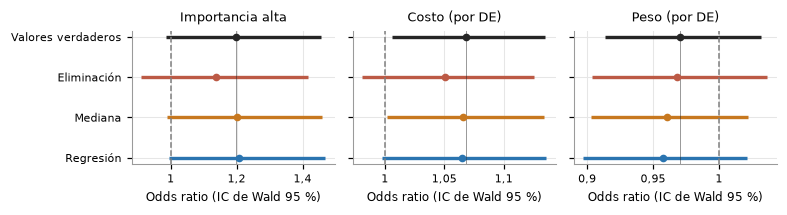

In [28]:
fig, axes = plt.subplots(1, len(cols_fin), figsize=(7.2, 2.0), sharey=True)
colores_est = {"Valores verdaderos": C_VERDADERO, "Eliminación": C_FUERA, "Mediana": COLORES["M2"], "Regresión": COLORES["M1"]}
nombres_est = list(CONJUNTOS_IMPACTO)
for ax, t in zip(np.atleast_1d(axes), cols_fin):
    for i, nombre in enumerate(nombres_est):
        r = impacto.set_index("estrategia").loc[nombre]
        yv = len(nombres_est) - 1 - i
        ax.plot([np.exp(r[f"inf_{t}"]), np.exp(r[f"sup_{t}"])], [yv, yv], color=colores_est[nombre], lw=2.2, solid_capstyle="butt")
        ax.scatter(np.exp(r[f"coef_{t}"]), yv, color=colores_est[nombre], s=16, zorder=3)
    ax.axvline(1, color=C_GRIS, ls="--", lw=1)
    ax.axvline(np.exp(ref.params[t]), color=C_VERDADERO, lw=0.6, alpha=0.5)
    ax.set_title(etiqueta[t]); ax.set_xlabel("Odds ratio (IC de Wald 95 %)")
np.atleast_1d(axes)[0].set_yticks(range(len(nombres_est))[::-1], nombres_est)
fig.tight_layout()
guardar_figura(fig, "s3_fig05_impacto_imputacion")
plt.show()

In [29]:
im = impacto.set_index("estrategia")
desv = {n: max(abs(im.loc[n, f"desvio_vs_verdadero_ee_{t}"]) for t in cols_fin) for n in im.index if n != "Valores verdaderos"}
mas_cerca = min(desv, key=desv.get)
display(Markdown(
    f"**Lectura.** La estrategia de faltantes **no cambia las conclusiones**. Con las tres, y con los valores verdaderos, la importancia alta tiene OR > 1 con un IC que "
    f"incluye 1, el costo un efecto positivo pequeño y el peso un efecto negativo cercano a 0. El AUC de prueba va de {es(im['auc_prueba'].min(), 3)} a {es(im['auc_prueba'].max(), 3)}: "
    f"siempre indistinguible del azar. Medido contra el ajuste con valores verdaderos, el mayor desvío de un coeficiente es "
    f"{es(desv['Eliminación'], 2)} errores estándar con la eliminación, {es(desv['Mediana'], 2)} con la mediana y {es(desv['Regresión'], 2)} con la regresión. "
    f"Los tres desvíos son menores que un error estándar: para el modelo, las estrategias son equivalentes. "
    f"La eliminación descarta {es(im.loc['Valores verdaderos', 'n_entrenamiento'] - im.loc['Eliminación', 'n_entrenamiento'], 0)} envíos de entrenamiento y ensancha los IC, "
    f"pero con faltantes MCAR no introduce sesgo sistemático. La regresión desplaza algo más el coeficiente del peso "
    f"({es(im.loc['Regresión', 'desvio_vs_verdadero_ee_Weight_in_gms'], 2)} EE), consecuencia de haber exagerado la correlación costo-peso (sección 1.3). "
    f"**Recomendación:** mantener la imputación por regresión. Tiene el menor error de imputación y conserva el tamaño muestral, y su efecto sobre las conclusiones es nulo. "
    f"Con faltantes MAR la eliminación dejaría de ser insesgada y la ventaja de imputar con predictores sería mayor. Si el peso fuera un predictor central, convendría PMM o "
    f"imputación múltiple, que conservan su forma bimodal y propagan la incertidumbre de la imputación a los errores estándar."
))

**Lectura.** La estrategia de faltantes **no cambia las conclusiones**. Con las tres, y con los valores verdaderos, la importancia alta tiene OR > 1 con un IC que incluye 1, el costo un efecto positivo pequeño y el peso un efecto negativo cercano a 0. El AUC de prueba va de 0,510 a 0,518: siempre indistinguible del azar. Medido contra el ajuste con valores verdaderos, el mayor desvío de un coeficiente es 0,54 errores estándar con la eliminación, 0,34 con la mediana y 0,45 con la regresión. Los tres desvíos son menores que un error estándar: para el modelo, las estrategias son equivalentes. La eliminación descarta 1.213 envíos de entrenamiento y ensancha los IC, pero con faltantes MCAR no introduce sesgo sistemático. La regresión desplaza algo más el coeficiente del peso (−0,45 EE), consecuencia de haber exagerado la correlación costo-peso (sección 1.3). **Recomendación:** mantener la imputación por regresión. Tiene el menor error de imputación y conserva el tamaño muestral, y su efecto sobre las conclusiones es nulo. Con faltantes MAR la eliminación dejaría de ser insesgada y la ventaja de imputar con predictores sería mayor. Si el peso fuera un predictor central, convendría PMM o imputación múltiple, que conservan su forma bimodal y propagan la incertidumbre de la imputación a los errores estándar.

## 4. Integración: el bloque inicial, las recomendaciones de S2 y la síntesis

### 4.1 Contraste con el conjunto completo

S2 recomendó repetir el modelo en el conjunto completo como sensibilidad y respetar el orden del archivo en la partición (recomendación 1). El indicador del bloque no se puede incluir como predictor: todos los envíos con ID ≤ 3.135 están fuera de plazo, así que el indicador **separa perfectamente** la clase y su coeficiente de máxima verosimilitud diverge a infinito. Se comparan, con las variables de M1 y agregando el descuento, dos particiones del archivo completo (valores originales, sin faltantes):

1. **Aleatoria estratificada 70/30**, como en el subconjunto. El bloque inicial queda repartido entre entrenamiento y prueba.
2. **Respetando el orden por ID:** entrenamiento con el primer 70 % del archivo, que contiene todo el bloque, y prueba con el 30 % final, como si se predijeran envíos posteriores.

In [30]:
full = df_original.copy()
X_full = matriz(full)
y_full = full[OBJETIVO].to_numpy()
ent_a, pru_a = train_test_split(np.arange(len(full)), test_size=0.30, stratify=y_full, random_state=SEED)
orden = np.argsort(full["ID"].to_numpy())
corte = int(round(0.70 * len(full)))
ent_o, pru_o = orden[:corte], orden[corte:]
escenarios = []
for part_nombre, (ie, ip) in {"Aleatoria estratificada": (ent_a, pru_a), "Respetando el orden por ID": (ent_o, pru_o)}.items():
    for var_nombre, cols in {"Variables de M1": cols_fin, "M1 + descuento": cols_fin + ["Discount_offered"]}.items():
        m = sm.Logit(y_full[ie], sm.add_constant(X_full.iloc[ie][cols], has_constant="add")).fit(disp=0, maxiter=500)
        prob = m.predict(sm.add_constant(X_full.iloc[ip][cols], has_constant="add")).to_numpy()
        auc, ic, pp, _ = inferencia_auc(y_full[ip], prob, SEED)
        escenarios.append({"particion": part_nombre, "variables": var_nombre, "n_prueba": len(ip),
                           "pct_bloque_en_prueba": 100 * np.mean(full["ID"].to_numpy()[ip] <= CORTE_ID),
                           "tasa_retraso_prueba": y_full[ip].mean(), "auc_prueba": auc, "auc_ic_inf": ic[0], "auc_ic_sup": ic[1], "p_permutacion": pp})
f_sub = desempeno.set_index("modelo").loc[FINAL]
escenarios.insert(0, {"particion": "ID > 3.135 (modelo final)", "variables": "Variables de M1", "n_prueba": len(y_pru), "pct_bloque_en_prueba": 0.0,
                      "tasa_retraso_prueba": y_pru.mean(), "auc_prueba": f_sub["auc_prueba"], "auc_ic_inf": f_sub["auc_ic_inf"],
                      "auc_ic_sup": f_sub["auc_ic_sup"], "p_permutacion": f_sub["p_permutacion"]})
contraste = guardar_tabla(pd.DataFrame(escenarios), "s3_tab16_contraste_bloque")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(contraste)

,particion,variables,n_prueba,pct_bloque_en_prueba,tasa_retraso_prueba,auc_prueba,auc_ic_inf,auc_ic_sup,p_permutacion
0,ID > 3.135 (modelo final),Variables de M1,2360,0.0000,0.4360,0.5153,0.4922,0.5392,0.1040
1,Aleatoria estratificada,Variables de M1,3300,27.9091,0.5967,0.6766,0.6579,0.6944,0.0001
2,Aleatoria estratificada,M1 + descuento,3300,27.9091,0.5967,0.7189,0.7019,0.7360,0.0001
3,Respetando el orden por ID,Variables de M1,3300,0.0000,0.4279,0.5013,0.4817,0.5213,0.4499
4,Respetando el orden por ID,M1 + descuento,3300,0.0000,0.4279,0.5010,0.4814,0.5209,0.4561


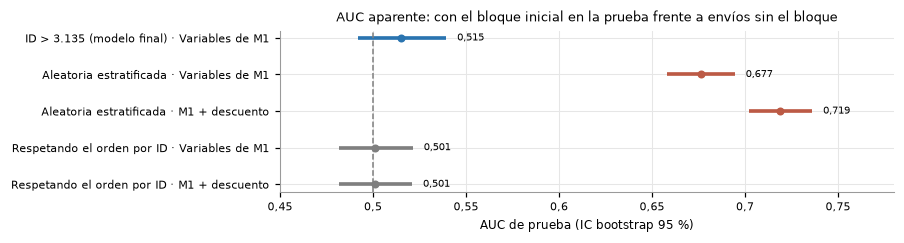

In [31]:
fig, ax = plt.subplots(figsize=(7.2, 1.9))
etq = [f"{r.particion} · {r.variables}" for r in contraste.itertuples()]
yy = np.arange(len(contraste))[::-1]
for y0, r in zip(yy, contraste.itertuples()):
    color = COLORES["M1"] if r.particion.startswith("ID") else (C_FUERA if r.particion.startswith("Aleatoria") else C_GRIS)
    ax.plot([r.auc_ic_inf, r.auc_ic_sup], [y0, y0], color=color, lw=2.4, solid_capstyle="butt")
    ax.scatter(r.auc_prueba, y0, color=color, s=18, zorder=3)
    ax.text(r.auc_ic_sup + 0.006, y0, es(r.auc_prueba, 3), va="center", fontsize=6.5)
ax.axvline(0.5, color=C_GRIS, ls="--", lw=1)
ax.set_yticks(yy, etq); ax.set_xlabel("AUC de prueba (IC bootstrap 95 %)"); ax.set_xlim(0.45, 0.78)
ax.set_title("AUC aparente: con el bloque inicial en la prueba frente a envíos sin el bloque")
guardar_figura(fig, "s3_fig06_contraste_bloque")
plt.show()

In [32]:
c_ = contraste.set_index(["particion", "variables"])
a1 = c_.loc[("Aleatoria estratificada", "Variables de M1")]
a2 = c_.loc[("Aleatoria estratificada", "M1 + descuento")]
o1 = c_.loc[("Respetando el orden por ID", "Variables de M1")]
o2 = c_.loc[("Respetando el orden por ID", "M1 + descuento")]
display(Markdown(
    f"**Lectura.** Con la partición aleatoria del archivo completo, el mismo modelo alcanza un AUC de {es(a1['auc_prueba'], 3)}, "
    f"y de {es(a2['auc_prueba'], 3)} al agregar el descuento: valores que en la escala del curso se leerían como «pobres a aceptables». "
    f"Pero el {es(a1['pct_bloque_en_prueba'], 1)} % de esa prueba pertenece al bloque inicial, que el modelo reconoce por su peso, su costo y su descuento atípicos. "
    f"Cuando la prueba son los envíos posteriores (30 % final del archivo, {es(o1['pct_bloque_en_prueba'], 1)} % del bloque), el AUC cae a {es(o1['auc_prueba'], 3)} y {es(o2['auc_prueba'], 3)}, "
    f"igual que en ID > 3.135. **El desempeño aparente de un modelo ajustado sobre el archivo completo proviene del bloque inicial, no de una relación que se repita en "
    f"envíos nuevos.** Es la consecuencia predictiva del hallazgo de S1 y de la dependencia según el orden que detectó el bootstrap por bloques de S2."
))

**Lectura.** Con la partición aleatoria del archivo completo, el mismo modelo alcanza un AUC de 0,677, y de 0,719 al agregar el descuento: valores que en la escala del curso se leerían como «pobres a aceptables». Pero el 27,9 % de esa prueba pertenece al bloque inicial, que el modelo reconoce por su peso, su costo y su descuento atípicos. Cuando la prueba son los envíos posteriores (30 % final del archivo, 0,0 % del bloque), el AUC cae a 0,501 y 0,501, igual que en ID > 3.135. **El desempeño aparente de un modelo ajustado sobre el archivo completo proviene del bloque inicial, no de una relación que se repita en envíos nuevos.** Es la consecuencia predictiva del hallazgo de S1 y de la dependencia según el orden que detectó el bootstrap por bloques de S2.

### 4.2 Recomendaciones de S2 ejecutadas en S3

El reporte de resultados validados de S2 dejó ocho recomendaciones metodológicas. La tabla registra cómo se aplicó cada una y dónde.

In [33]:
f_ = frec_sel.set_index("variable")["frecuencia_seleccion_pct"]
traza = guardar_tabla(pd.DataFrame([
    {"recomendacion_S2": "1. Modelar en ID > 3.135; repetir en el completo; partición que respete el orden",
     "aplicacion_S3": f"Modelos en ID > 3.135. En el completo, partición aleatoria (AUC {es(a1['auc_prueba'], 3)}) frente a partición por orden ({es(o1['auc_prueba'], 3)}). "
                      "En ID > 3.135, partición aleatoria justificada por el bootstrap por bloques (sin estructura por orden)", "seccion": "0.2, 2, 4.1"},
    {"recomendacion_S2": "2. Descuento y separación casi perfecta (Firth)",
     "aplicacion_S3": "En ID > 3.135 no hay separación y no se usa Firth. El indicador del bloque no se incluye porque separa perfectamente", "seccion": "2.2, 4.1"},
    {"recomendacion_S2": "3. Fuga de información (descuento, llamadas, calificación)",
     "aplicacion_S3": "Llamadas y calificación excluidas como predictores y como variables de imputación; el descuento, ofrecido en la venta, queda como candidato", "seccion": "1.2, 2.1"},
    {"recomendacion_S2": "4. Importancia alta como candidata exploratoria; potencia de 49 %",
     "aplicacion_S3": "Está en los tres modelos. OR > 1 en todos, sin significancia tras Holm, coherente con la potencia baja", "seccion": "2.2"},
    {"recomendacion_S2": "5. Imputar el peso sin supuesto normal (residuos empíricos o PMM)",
     "aplicacion_S3": "Regresión como estrategia principal; regresión con residuo empírico y PMM como sensibilidad. PMM conserva la bimodalidad", "seccion": "1.3"},
    {"recomendacion_S2": "6. Línea base de clase mayoritaria y métricas más allá de la accuracy",
     "aplicacion_S3": f"Línea base de {pct(1 - y_pru.mean())} de accuracy; se informan recall, precision, F1, especificidad, AUC con IC y prueba de permutación", "seccion": "2.5"},
    {"recomendacion_S2": "7. Bootstrap BCa con B ≥ 10.000 para coeficientes",
     "aplicacion_S3": f"BCa y percentil con {B_BOOT:,} remuestras y aceleración por jackknife; frecuencia de selección del stepwise en {B_SEL:,} remuestras".replace(",", "."), "seccion": "2.3"},
    {"recomendacion_S2": "8. Holm para varios predictores",
     "aplicacion_S3": "p ajustados por Holm en los coeficientes de cada modelo", "seccion": "2.2"},
]), "s3_tab17_trazabilidad_s2")
display(traza)

,recomendacion_S2,aplicacion_S3,seccion
0,1. Modelar en ID > 3.135; repetir en el comple...,"Modelos en ID > 3.135. En el completo, partici...","0.2, 2, 4.1"
1,2. Descuento y separación casi perfecta (Firth),En ID > 3.135 no hay separación y no se usa Fi...,"2.2, 4.1"
2,"3. Fuga de información (descuento, llamadas, c...",Llamadas y calificación excluidas como predict...,"1.2, 2.1"
3,4. Importancia alta como candidata exploratori...,"Está en los tres modelos. OR > 1 en todos, sin...",2.2
4,5. Imputar el peso sin supuesto normal (residu...,Regresión como estrategia principal; regresión...,1.3
5,6. Línea base de clase mayoritaria y métricas ...,"Línea base de 56,4 % de accuracy; se informan ...",2.5
6,7. Bootstrap BCa con B ≥ 10.000 para coeficientes,BCa y percentil con 10.000 remuestras y aceler...,2.3
7,8. Holm para varios predictores,p ajustados por Holm en los coeficientes de ca...,2.2


### 4.3 Síntesis integrada

**Resumen ejecutivo.** Se construyó un modelo de regresión logística para anticipar el incumplimiento de plazos en el régimen de envíos ID > 3.135, con predictores conocidos antes del despacho. El modelo final (M1: importancia alta, costo y peso) cumple los supuestos y está bien calibrado. Sus coeficientes se estiman con precisión, y los IC bootstrap de 10.000 remuestras coinciden con los de Wald. Pero **no discrimina mejor que el azar**: AUC de prueba 0,515 [0,492; 0,539], prueba de permutación p = 0,104. La conclusión del proyecto es que, sin el bloque inicial, las variables disponibles no permiten predecir qué envíos se retrasarán.

**Faltantes.** Sobre el 12 % MCAR inducido en costo y peso, la imputación por regresión lineal múltiple (R² de 0,21 y 0,30) redujo el error de imputación frente a la mediana: el RMSE del peso bajó de 1.635 g a 1.311 g. Además conservó los 7.864 envíos, contra los 6.085 de la eliminación. Sus costos son el encogimiento de la varianza, una correlación costo-peso exagerada y pesos imputados en el rango 2.000-3.999 g (el 43,6 % de los imputados; 5,2 % de todos los pesos), donde los datos reales tienen 0,04 %. El modelo final ajustado con eliminación, mediana, regresión y valores verdaderos llega a la misma conclusión, con desvíos menores que un error estándar.

**Modelos y estabilidad.** El stepwise por AIC eligió costo, importancia y descuento, pero el descuento aparece solo en el 52,4 % de las remuestras bootstrap. BIC no eligió ninguna variable. La regla de un error estándar sobre la validación cruzada seleccionó M1. Ninguno de sus tres coeficientes es estable: los IC BCa de la importancia alta (OR = 1,21), el costo (OR = 1,065 por desviación estándar) y el peso incluyen OR = 1.

**Progresión S1 → S2 → S3.** S1 encontró asociaciones fuertes y el bloque inicial. S2 mostró que esas asociaciones dependen del bloque. S3 cierra el argumento en su dimensión predictiva: el mismo modelo pasa de un AUC de 0,677 en una partición aleatoria del archivo completo a 0,501 cuando se evalúa en envíos posteriores. El desempeño aparente es la huella del bloque.

**Recomendaciones.**

1. **Operación:** no usar estas variables para priorizar envíos con riesgo de retraso.
2. **Investigar el bloque inicial:** es la principal fuente de variación del archivo.
3. **Ampliar los datos:** con unos 14.000 envíos se tendría una potencia de 80 % para la diferencia de la importancia alta (S2). Además, faltan variables del proceso logístico (fechas, transportista, distancia, carga) que hoy no están en la base.
4. **Validar con envíos posteriores** antes de usar cualquier modelo en la operación.

### Control de consistencia

Verifica que cada cifra citada en Markdown (sección 1.2 y síntesis 4.3) coincida con el cálculo de este notebook.

In [34]:
r_ = lambda x, d: round(float(x), d)
cmp_ = comparacion_imp.set_index("estrategia")
fin_ = desempeno.set_index("modelo").loc[FINAL]
bt_ = boot_tab.set_index("termino")
citas = {
    "Envíos sin ambos valores en entrenamiento: 75": (int(ent0[VARS_FALTANTES].isna().all(axis=1).sum()), 75),
    "Envíos sin ambos valores en prueba: 41": (int(pru0[VARS_FALTANTES].isna().all(axis=1).sum()), 41),
    "Modelo final M1": (FINAL, "M1"),
    "AUC prueba 0,515": (r_(fin_["auc_prueba"], 3), 0.515),
    "IC AUC inferior 0,492": (r_(fin_["auc_ic_inf"], 3), 0.492),
    "IC AUC superior 0,539": (r_(fin_["auc_ic_sup"], 3), 0.539),
    "p permutación 0,104": (r_(fin_["p_permutacion"], 3), 0.104),
    "R² costo 0,21": (r_(diag_imp.set_index("variable").loc["Costo", "R2"], 2), 0.21),
    "R² peso 0,30": (r_(diag_imp.set_index("variable").loc["Peso", "R2"], 2), 0.30),
    "RMSE peso mediana 1.635 g": (r_(cmp_.loc["Mediana", "rmse_peso"], 0), 1635.0),
    "RMSE peso regresión 1.311 g": (r_(cmp_.loc["Regresión", "rmse_peso"], 0), 1311.0),
    "n eliminación 6.085": (int(cmp_.loc["Eliminación", "n_entrenamiento"] + cmp_.loc["Eliminación", "n_prueba"]), 6085),
    "pesos imputados en el hueco 5,2 %": (r_(cmp_.loc["Regresión", "pct_peso_hueco_2000_3999"], 1), 5.2),
    "imputados en el hueco 43,6 %": (r_(cmp_.loc["Regresión", "pct_imputados_en_hueco"], 1), 43.6),
    "pesos verdaderos en el hueco 0,04 %": (r_(cmp_.loc["Valores verdaderos (referencia)", "pct_peso_hueco_2000_3999"], 2), 0.04),
    "desvíos de impacto < 1 EE": (bool(max(abs(impacto[[c for c in impacto.columns if c.startswith("desvio")]].to_numpy().ravel())) < 1), True),
    "stepwise AIC elige costo, importancia, descuento": (set(sel_aic), {"Costo", "Importancia", "Descuento"}),
    "descuento en 52,4 % de remuestras": (r_(f_["Descuento"], 1), 52.4),
    "BIC no elige variables": (len(sel_bic), 0),
    "OR costo 1,065": (r_(bt_.loc["Costo (por DE)", "OR"], 3), 1.065),
    "OR importancia alta 1,21": (r_(bt_.loc["Importancia alta", "OR"], 2), 1.21),
    "los tres coeficientes inestables": (int(bt_["estado"].str.startswith("Inestable").sum()), 3),
    "AUC completo aleatorio 0,677": (r_(a1["auc_prueba"], 3), 0.677),
    "AUC completo por orden 0,501": (r_(o1["auc_prueba"], 3), 0.501),
}
fallas = {k: v for k, v in citas.items() if v[0] != v[1]}
for k, (calc, texto) in citas.items():
    print(f"{'OK ' if calc == texto else 'ERROR'} {k}: calculado {calc}")
assert not fallas, f"Cifras desactualizadas: {fallas}"
print(f"\nTablas: {len(list(DIR_TABLAS.glob('s3_*.csv')))} · figuras: {len(list(DIR_FIGURAS.glob('s3_*.png')))} · "
      f"tiempo total: {(time.time() - T0) / 60:.1f} min")

OK  Envíos sin ambos valores en entrenamiento: 75: calculado 75
OK  Envíos sin ambos valores en prueba: 41: calculado 41
OK  Modelo final M1: calculado M1
OK  AUC prueba 0,515: calculado 0.515
OK  IC AUC inferior 0,492: calculado 0.492
OK  IC AUC superior 0,539: calculado 0.539
OK  p permutación 0,104: calculado 0.104
OK  R² costo 0,21: calculado 0.21
OK  R² peso 0,30: calculado 0.3
OK  RMSE peso mediana 1.635 g: calculado 1635.0
OK  RMSE peso regresión 1.311 g: calculado 1311.0
OK  n eliminación 6.085: calculado 6085
OK  pesos imputados en el hueco 5,2 %: calculado 5.2
OK  imputados en el hueco 43,6 %: calculado 43.6
OK  pesos verdaderos en el hueco 0,04 %: calculado 0.04
OK  desvíos de impacto < 1 EE: calculado True
OK  stepwise AIC elige costo, importancia, descuento: calculado {'Costo', 'Descuento', 'Importancia'}
OK  descuento en 52,4 % de remuestras: calculado 52.4
OK  BIC no elige variables: calculado 0
OK  OR costo 1,065: calculado 1.065
OK  OR importancia alta 1,21: calculado 